<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-07/central-england-temperature.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Forecasting the weather in central England

*Deep Learning for Scientific Discovery, Jagiellonian University. Author: Marcin Płodzień.*



Weather forecasting is the oldest and most successful application of forecasting in the natural sciences. Since the 1950s weather services have integrated the equations of fluid dynamics of the atmosphere on computers, the numerical weather prediction that Lorenz studied when he found the chaotic model of the lecture. Lorenz showed that small errors of the initial state grow until the forecast is no better than a guess, so that there is a limit to the horizon of any weather forecast, and modern forecasts of the daily temperature remain useful for about a week to ten days. Weather forecasters judge every forecast against two simple references. Persistence forecasts that tomorrow will be like today. Climatology forecasts the long-term average for that day of the year. A forecast method has skill only when it beats both.

The daily mean temperature of central England forms the longest instrumental record of temperature in the world, with daily values since 1772 and monthly values since 1659. We forecast it with the models of the lecture, which see only the past temperatures and nothing of the state of the atmosphere around them. The record shows two effects that every forecaster of a measured signal has to handle. The seasonal cycle is a large and predictable oscillation that a forecast reproduces easily and that tells nothing about the weather. A slow trend records the warming of the climate.

We analyse the measured temperature record using the same forecasting procedure as for the S&P 500 index and El Niño exercises. The measurement procedure and data source establish what each value represents. The time plot, histogram, autocorrelation function, power spectrum and delay plot describe its statistical properties and separate the seasonal cycle from the weather. Persistence and climatology provide reference forecasts of the temperature itself. We also forecast the temperature anomaly, the departure from the seasonal cycle, up to 20 days ahead with the models of the lecture, from the autoregressive (AR), moving-average (MA) and combined (ARMA) models through the nonlinear vector autoregression (NVAR) to a multilayer perceptron (MLP), an Elman recurrent neural network (RNN) and a long short-term memory network (LSTM). For every model we plot the forecasts against the true values at the horizons τ = 1, 5 and 20 days and the capacity C(τ) against τ, and we collect the total capacities in one table.

> **Google Colab execution**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*. The setting `JAX_PLATFORMS=cpu` selects CPU execution, which takes a few minutes.
> 2. `jax`, `flax`, `optax`, `statsmodels`, `scikit-learn`, `scipy`, `pandas` and `matplotlib` are pre-installed in Colab.
> 3. The data are downloaded from the Met Office Hadley Centre during execution, so an internet connection is needed.
> 4. Run the cells *in order*. Later cells use variables defined earlier.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)
import time, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import scipy.stats
import scipy.signal
import jax, jax.numpy as jnp
import optax
import flax
from flax import nnx
import sklearn
from sklearn.neural_network import MLPRegressor
import statsmodels
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import acf
warnings.filterwarnings("ignore", module="statsmodels")
warnings.filterwarnings("ignore", category=sklearn.exceptions.ConvergenceWarning)

plt.rcParams.update({"font.size": 15, "axes.titlesize": 16, "axes.labelsize": 15, "xtick.labelsize": 13,
                     "ytick.labelsize": 13, "legend.fontsize": 13, "figure.titlesize": 17,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)
t_start = time.time()
print("jax", jax.__version__, "| flax", flax.__version__, "| optax", optax.__version__,
      "| statsmodels", statsmodels.__version__, "| scikit-learn", sklearn.__version__)

jax 0.11.0 | flax 0.12.8 | optax 0.2.6 | statsmodels 0.14.4 | scikit-learn 1.6.1


<hr/>
## 1. The Central England Temperature

The Central England Temperature (CET) is the daily mean air temperature representative of a roughly triangular area of England enclosed by Lancashire, London and Bristol. Gordon Manley compiled the monthly series from 1659 to 1973 from old diaries and instrument records, and Parker, Legg and Folland built the daily series from 1772 [D. E. Parker, T. P. Legg, C. K. Folland, Int. J. Climatol. **12**, 317 (1992), [doi:10.1002/joc.3370120402](https://doi.org/10.1002/joc.3370120402)]. The Met Office Hadley Centre keeps the series up to date from a small set of weather stations in the area, whose readings are combined and adjusted so that the series stays consistent when stations change. Since 1974 a correction of −0.2 °C is applied to account for the warming of the stations by the growing towns around them. The current version 2.1 is described by Legg and co-workers [T. Legg, D. Packman, G. Caton Harrison, M. McCarthy, Geosci. Data J. **12**, e284 (2025), [doi:10.1002/gdj3.284](https://doi.org/10.1002/gdj3.284)].

One sample of the record is the mean temperature of one day in °C, the average of the daily maximum and minimum temperatures. The file has two columns, the date and the value.

> Source: Met Office Hadley Centre, *HadCET daily mean temperature*, version 2.1, <https://www.metoffice.gov.uk/hadobs/hadcet/>. The data are available under the Open Government Licence. Contains public sector information licensed under the Open Government Licence v3.0.

In [2]:
CET_URL = "https://www.metoffice.gov.uk/hadobs/hadcet/data/meantemp_daily_totals.txt"
CET_FILE = "data/meantemp_daily_totals.txt"
if not os.path.exists(CET_FILE):
    urllib.request.urlretrieve(CET_URL, CET_FILE)
cet_all = pd.read_csv(CET_FILE, sep=r"\s+", parse_dates=["Date"])
print(f"{len(cet_all)} days, {cet_all.Date.iloc[0].date()} to {cet_all.Date.iloc[-1].date()}, "
      f"missing values: {int(cet_all.Value.isna().sum())}")
print(cet_all.tail(4).to_string(index=False))

93071 days, 1772-01-01 to 2026-10-26, missing values: 0
      Date  Value
2026-10-23    9.9
2026-10-24   10.0
2026-10-25   10.1
2026-10-26   11.3


The record has 93071 days, from 1 January 1772 to 26 October 2026, without a missing value. The last rows show the daily means of late October 2026, around 10 °C.

The Central England Temperature represents the triangle between Lancashire, London and Bristol. The station diagram marks the approximate positions of these places. Each station records the maximum and minimum temperature of every day, whose average gives the daily mean. The measurements over one week illustrate this averaging. The daily means of the stations in the triangle are combined into one value per day, the sample $T_k$ of our record.

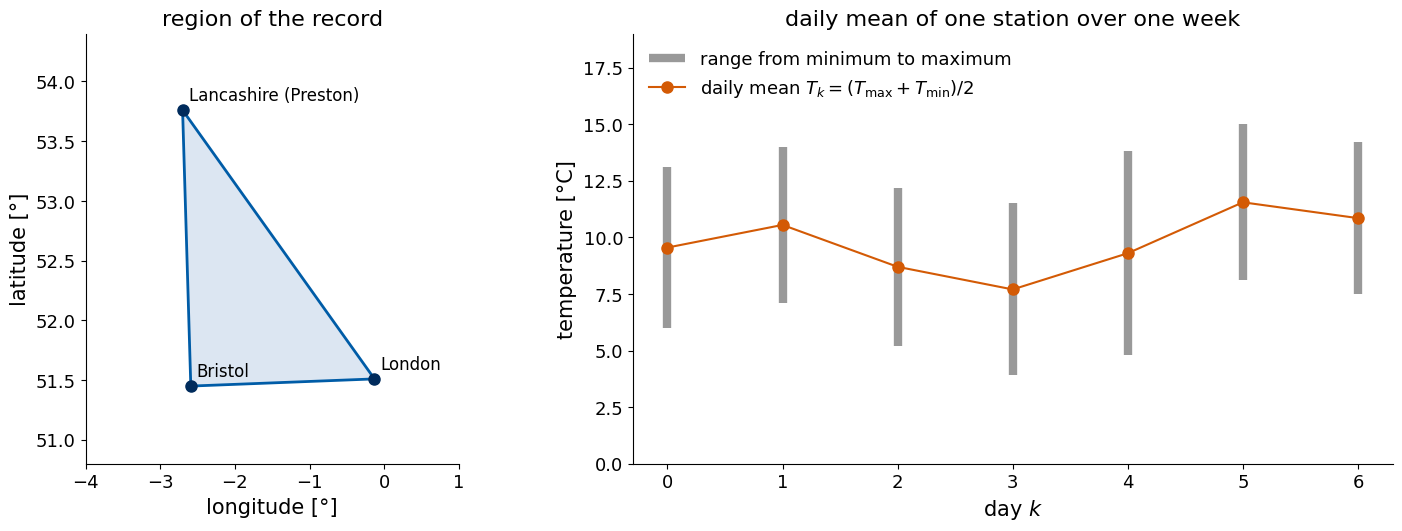

In [3]:
# sketch of the CET region: the triangle Lancashire - London - Bristol (approximate positions)
places = {"Lancashire (Preston)": (-2.70, 53.76), "London": (-0.13, 51.51), "Bristol": (-2.59, 51.45)}
fig, axs = plt.subplots(1, 2, figsize=(14, 5.2), layout="constrained", gridspec_kw={"width_ratios": [1, 1.4]})
xy = np.array(list(places.values()))
axs[0].fill(xy[:, 0], xy[:, 1], color="#DCE6F2", edgecolor=UJBlue, lw=2)
for name, (lo, la) in places.items():
    axs[0].plot(lo, la, "o", color=UJNavy, ms=8)
    axs[0].text(lo + 0.08, la + 0.08, name, fontsize=12)
axs[0].set_xlim(-4, 1); axs[0].set_ylim(50.8, 54.4); axs[0].set_aspect(1.6)
axs[0].set_xlabel("longitude [°]"); axs[0].set_ylabel("latitude [°]"); axs[0].set_title("region of the record")
days = np.arange(7)
tmax = np.array([13.1, 14.0, 12.2, 11.5, 13.8, 15.0, 14.2]); tmin = np.array([6.0, 7.1, 5.2, 3.9, 4.8, 8.1, 7.5])
axs[1].vlines(days, tmin, tmax, color="0.6", lw=6, label="range from minimum to maximum")
axs[1].plot(days, (tmax + tmin) / 2, "o-", color=DSOrange, ms=8, label=r"daily mean $T_k = (T_{\max} + T_{\min})/2$")
axs[1].set_xlabel("day $k$"); axs[1].set_ylabel("temperature [°C]"); axs[1].set_ylim(0, 19); axs[1].legend(loc="upper left")
axs[1].set_title("daily mean of one station over one week")
plt.show()

<hr/>
## 2. Statistical properties of a record

The statistical properties of a record indicate which forecasts can be expected to work. We examine its distribution, temporal correlations and periodic components before fitting a model.

The mean and the standard deviation give the level and the typical size of the fluctuations, and the histogram shows the distribution of the values, whether it is symmetric, bounded or has long tails.

The autocorrelation function measures the linear dependence between values separated in time. For a record $s_1,\dots,s_N$ with mean $\bar s$ it is
$$\rho(m)=\frac{\sum_{k=1}^{N-m}(s_k-\bar s)(s_{k+m}-\bar s)}{\sum_{k=1}^{N}(s_k-\bar s)^2} , \tag{1}$$
the correlation of the record with itself shifted by m steps. It equals 1 at m = 0 and lies between −1 and 1. A fast decay of ρ(m) to zero means a short memory, and the lag at which ρ(m) first drops below 1/e ≈ 0.37 is a common estimate of the correlation time. A record with a periodic component has an autocorrelation that oscillates with the same period. For N independent values, ρ(m) at m > 0 fluctuates around zero with a standard deviation of about $1/\sqrt N$, so values inside $\pm2/\sqrt N$ are compatible with no memory at all. When the lag equals a forecast horizon τ we write the same function as ρ(τ), the correlation between the value of today and the value τ steps later.

The power spectrum tells which periods are present in the record. The discrete Fourier transform writes the record as a sum of sinusoids with the frequencies $f_j=j/(N\Delta t)$, j = 0, 1, …, N/2, where Δt is the sampling interval,
$$X_j=\sum_{k=0}^{N-1}(s_k-\bar s)\,e^{-2\pi i jk/N} . \tag{2}$$
The magnitude $|X_j|$ says how strongly the frequency $f_j$ is present. The periodogram
$$P_j=\frac{\Delta t}{N}\,|X_j|^2 \tag{3}$$
is the simplest estimate of the power spectrum, the share of the variance of the record per unit of frequency. A peak at the frequency $f_j$ marks a periodic or nearly periodic component with the period $1/f_j$. The frequency resolution is $1/(N\Delta t)$, so a record of 100 years resolves frequencies to one cycle per 100 years. The periodogram fluctuates strongly from one frequency to the next, and the Welch method reduces this by cutting the record into overlapping segments, computing the periodogram of each and averaging, at the price of a coarser resolution. The power spectrum and the autocorrelation function carry the same information, since by the Wiener–Khinchin theorem one is the Fourier transform of the other.

The delay plot places every value $s_k$ against the value κ steps earlier, $s_{k-\kappa}$. This gives a two-dimensional delay embedding. A record from a low-dimensional deterministic law traces a thin curve or a structured band, a periodic record a closed loop, and a record without memory a round cloud.

We compute the autocorrelation of equation (1) and the periodogram of equation (3) with NumPy and check both against `statsmodels` and `scipy`.

In [4]:
def autocorrelation(x, max_lag):
    # equation (1) for m = 0, 1, ..., max_lag
    xc = x - x.mean()
    den = np.sum(xc ** 2)
    return np.array([np.sum(xc[:len(x) - m] * xc[m:]) / den for m in range(max_lag + 1)])

def periodogram(x, dt):
    # equations (2) and (3): frequencies f_j = j / (N dt) and P_j = dt |X_j|^2 / N
    X = np.fft.rfft(x - x.mean())
    f = np.fft.rfftfreq(len(x), d=dt)
    return f, dt * np.abs(X) ** 2 / len(x)

def correlation_time(rho):
    # first lag at which the autocorrelation drops below 1/e
    below = np.flatnonzero(rho < np.exp(-1))
    return int(below[0]) if below.size else None

_x = np.cumsum(np.random.default_rng(0).standard_normal(500)) * 0.1 + np.random.default_rng(1).standard_normal(500)
assert np.allclose(autocorrelation(_x, 30), acf(_x, nlags=30, fft=False))
_f, _P = periodogram(_x, 1.0)
_fs, _Ps = scipy.signal.periodogram(_x - _x.mean(), fs=1.0, scaling="density", detrend=False)
assert np.allclose(_P[1:-1], _Ps[1:-1] / 2)       # scipy counts both signs of the frequency in the one-sided density
print("autocorrelation agrees with statsmodels, periodogram agrees with scipy")

autocorrelation agrees with statsmodels, periodogram agrees with scipy


<hr/>
## 3. Temperature variations

A forecasting model learns a rule from the past and applies it to the future, so it needs a record whose statistical properties do not change in time. The whole record of 254 years is first reduced to yearly means, which show the slow changes of the climate that could break this assumption. The daily values of the last three years show the two faster components, the seasons and the weather.

mean of the first 30 complete years (1772-1801): 9.13 °C, of the last 30 (1996-2025): 10.45 °C
warmest year 2025 (11.23 °C), coldest 1879 (7.44 °C)


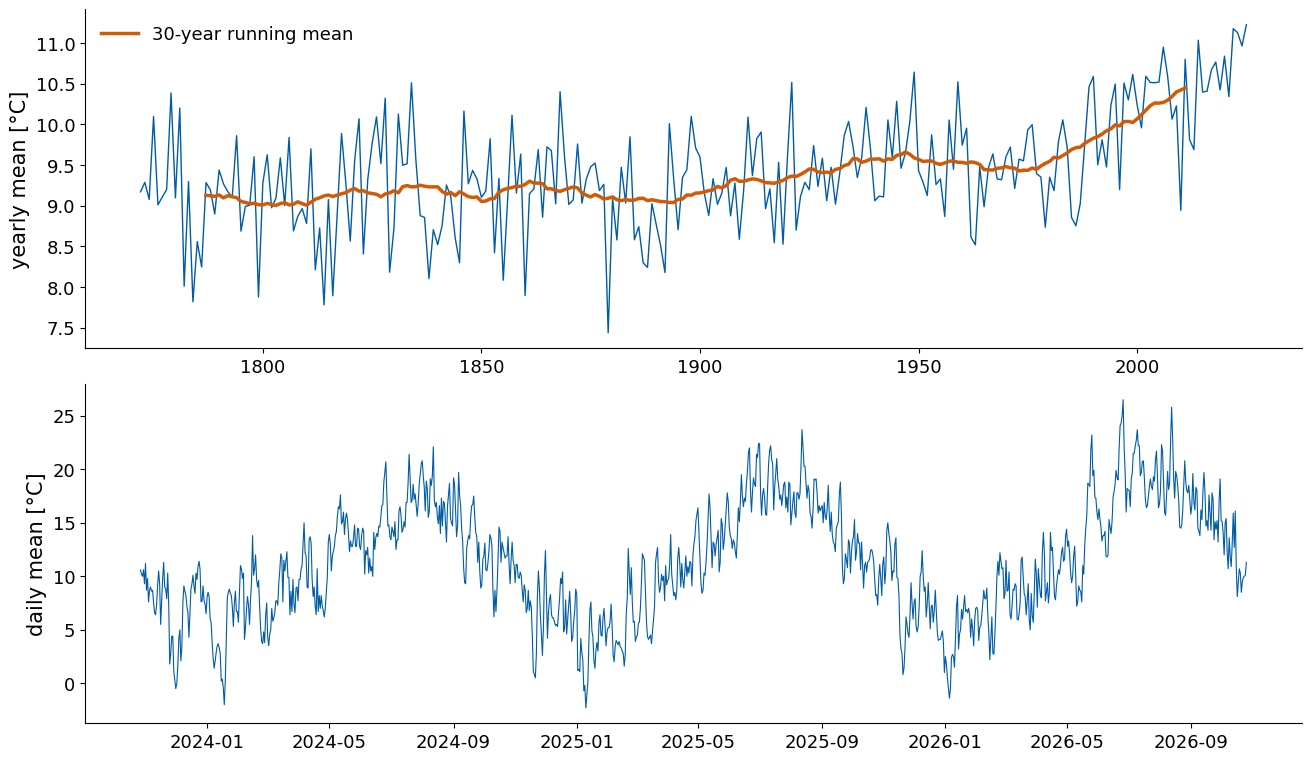

In [5]:
yearly = cet_all.groupby(cet_all.Date.dt.year).Value.agg(["mean", "count"])
yearly = yearly[yearly["count"] >= 365]                      # complete years only
fig, axs = plt.subplots(2, 1, figsize=(13, 7.5), layout="constrained")
axs[0].plot(yearly.index, yearly["mean"], color=UJBlue, lw=1)
axs[0].plot(yearly.index, yearly["mean"].rolling(30, center=True).mean(), color=DSOrange, lw=2.5, label="30-year running mean")
axs[0].set_ylabel("yearly mean [°C]"); axs[0].legend()
last = cet_all[cet_all.Date >= cet_all.Date.iloc[-1] - pd.Timedelta(days=3 * 365)]
axs[1].plot(last.Date, last.Value, color=UJBlue, lw=0.8)
axs[1].set_ylabel("daily mean [°C]")
plt.show()
first30, last30 = yearly["mean"].iloc[:30].mean(), yearly["mean"].iloc[-30:].mean()
print(f"mean of the first 30 complete years ({yearly.index[0]}-{yearly.index[29]}): {first30:.2f} °C, "
      f"of the last 30 ({yearly.index[-30]}-{yearly.index[-1]}): {last30:.2f} °C")
print(f"warmest year {yearly['mean'].idxmax()} ({yearly['mean'].max():.2f} °C), coldest {yearly['mean'].idxmin()} ({yearly['mean'].min():.2f} °C)")

The yearly means in the upper panel fluctuate by about one degree from year to year, and the 30-year running mean shows the slow change of the climate. The first 30 complete years, 1772 to 1801, had the mean 9.13 °C, and the last 30, 1996 to 2025, the mean 10.45 °C, a warming of 1.3 °C. The warmest year of the record is 2025 with 11.23 °C, and the coldest is 1879 with 7.44 °C. The daily values of the last three years in the lower panel show a large seasonal oscillation, from around 0 °C in winter to around 20 °C in summer, with irregular day-to-day weather on top of it.

For the forecasts we use the last thirty years, from 1 January 1996, a period in which the climate changes little compared with the day-to-day weather. The seasonal cycle of this period, the climatology, is described by a mean, an annual and a semi-annual oscillation,
$$c(t)=a_0+\sum_{h=1}^{2}\Big[a_h\cos\frac{2\pi h t}{365.25}+b_h\sin\frac{2\pi h t}{365.25}\Big] , \tag{4}$$
where t is the time in days and the five coefficients are fitted by least squares on the fitting block, the first 60% of the period. The anomaly of day k is the measured temperature minus the climatology,
$$a_k=T_k-c(t_k) , \tag{5}$$
the part of the temperature that the season does not explain, which is the weather.

11257 days from 1996-01-01 to 2026-10-26
climatology: mean 10.25 °C, amplitude of the annual cycle 6.30 °C, warmest day of the fitted cycle: day 213 of the year
standard deviation: temperature 5.19 °C, anomaly 2.64 °C; fraction of the variance explained by the climatology 0.74


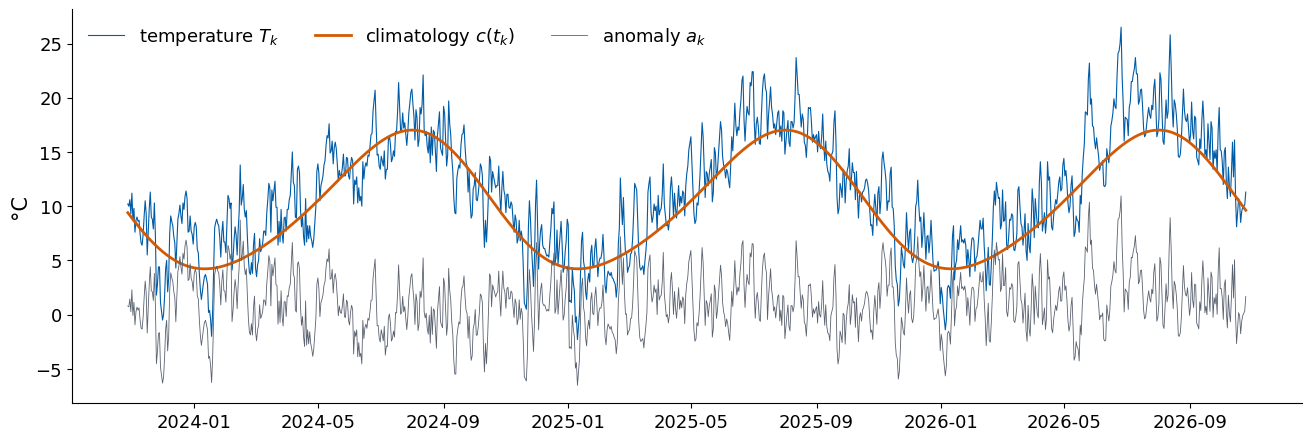

In [6]:
cet = cet_all[cet_all.Date >= "1996-01-01"].reset_index(drop=True)
temp = cet["Value"].to_numpy(float)
t_days = (cet.Date - cet.Date.iloc[0]).dt.days.to_numpy(float)
n_fit = int(0.6 * len(temp))

def harmonics(t):
    w = 2 * np.pi * t / 365.25
    return np.column_stack([np.ones_like(t), np.cos(w), np.sin(w), np.cos(2 * w), np.sin(2 * w)])

coef, *_ = np.linalg.lstsq(harmonics(t_days[:n_fit]), temp[:n_fit], rcond=None)     # equation (4)
clim = harmonics(t_days) @ coef
anom = temp - clim                                                                   # equation (5)
print(f"{len(temp)} days from {cet.Date.iloc[0].date()} to {cet.Date.iloc[-1].date()}")
print(f"climatology: mean {coef[0]:.2f} °C, amplitude of the annual cycle {np.hypot(coef[1], coef[2]):.2f} °C, "
      f"warmest day of the fitted cycle: day {int(np.argmax(clim[:366]))} of the year")
print(f"standard deviation: temperature {temp.std():.2f} °C, anomaly {anom.std():.2f} °C; "
      f"fraction of the variance explained by the climatology {1 - anom[:n_fit].var() / temp[:n_fit].var():.2f}")

fig, ax = plt.subplots(figsize=(13, 4.3), layout="constrained")
sel = slice(len(temp) - 3 * 365, len(temp))
ax.plot(cet.Date[sel], temp[sel], color=UJBlue, lw=0.8, label="temperature $T_k$")
ax.plot(cet.Date[sel], clim[sel], color=DSOrange, lw=2, label="climatology $c(t_k)$")
ax.plot(cet.Date[sel], anom[sel], color=UJGray, lw=0.6, label="anomaly $a_k$")
ax.set_ylabel("°C"); ax.legend(ncol=3, loc="upper left")
plt.show()

The period from 1 January 1996 has 11257 days. The fitted climatology has the mean 10.25 °C and an annual cycle with the amplitude 6.30 °C, so the typical summer day is about 12.6 °C warmer than the typical winter day, and the warmest day of the fitted cycle is day 213 of the year, at the beginning of August. The temperature has the standard deviation 5.19 °C and the anomaly 2.64 °C. The climatology explains 74% of the variance of the temperature in the fitting block, and the weather carries the remaining 26%. Over the last three years the climatology is a smooth curve and the anomaly fluctuates around zero.

The histogram shows how the values are distributed. Its shape decides whether a mean squared error, which weights large deviations strongly, is a sensible loss, and whether the record has hard bounds or rare extreme values that a forecast has to handle. The skewness measures the asymmetry of the distribution, zero for a symmetric one. We compare the temperature with its anomaly, to see which properties belong to the season and which to the weather.

temperature  mean  10.51 °C, std 5.19 °C, skewness -0.06, excess kurtosis -0.63
anomaly      mean   0.23 °C, std 2.64 °C, skewness  0.01, excess kurtosis  0.09


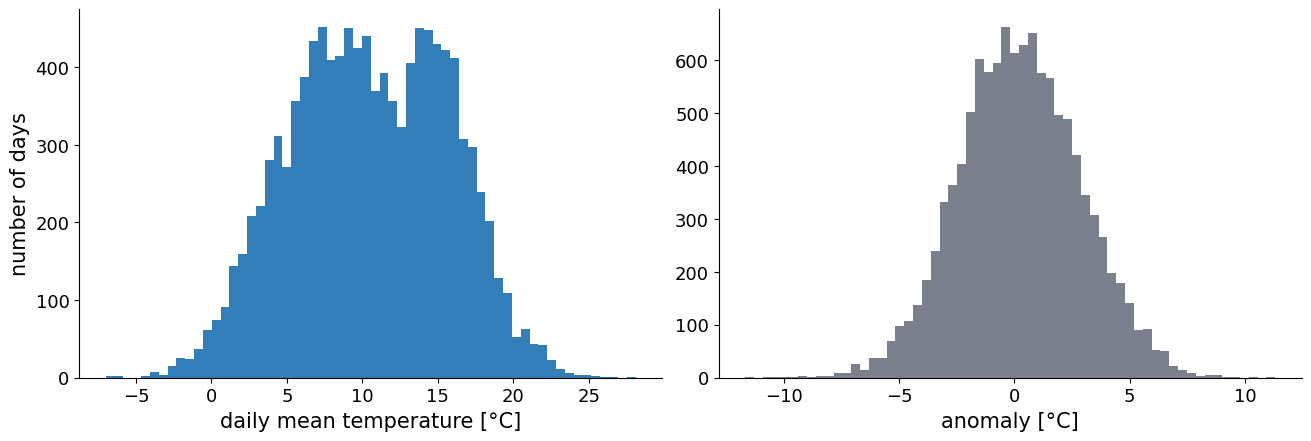

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.3), layout="constrained")
axs[0].hist(temp, bins=60, color=UJBlue, alpha=0.8); axs[0].set_xlabel("daily mean temperature [°C]")
axs[1].hist(anom, bins=60, color=UJGray, alpha=0.8); axs[1].set_xlabel("anomaly [°C]")
axs[0].set_ylabel("number of days")
plt.show()
for name, x in (("temperature", temp), ("anomaly", anom)):
    print(f"{name:12s} mean {x.mean():6.2f} °C, std {x.std():.2f} °C, skewness {scipy.stats.skew(x):5.2f}, "
          f"excess kurtosis {scipy.stats.kurtosis(x):5.2f}")

The temperature has the mean 10.51 °C, a skewness of −0.06 and an excess kurtosis of −0.63. Its histogram is broad and flat-topped, since it mixes the cold days of winter with the warm days of summer. The anomaly has a nearly Gaussian distribution, with a skewness of 0.01 and an excess kurtosis of 0.09. Its mean over the whole period is 0.23 °C. It differs from zero because the climatology was fitted on the earlier 60% of the period and the later years were warmer.

The autocorrelation function of equation (1) measures how long correlations persist in the record. Their duration sets the scale of the forecasts. Persistence reaches about $\rho(\tau)^2$ at the horizon τ, so the decay of ρ shows how fast the simplest forecast loses its skill, and an oscillation of ρ reveals a cycle that a model can continue. We compare the temperature with its anomaly, to see which properties belong to the season and which to the weather.

temperature: rho at 1, 182, 365 days = [ 0.944 -0.702  0.712]
anomaly: rho at 1, 2, 5, 10, 20 days = [0.784 0.56  0.257 0.087 0.034], correlation time 4 days


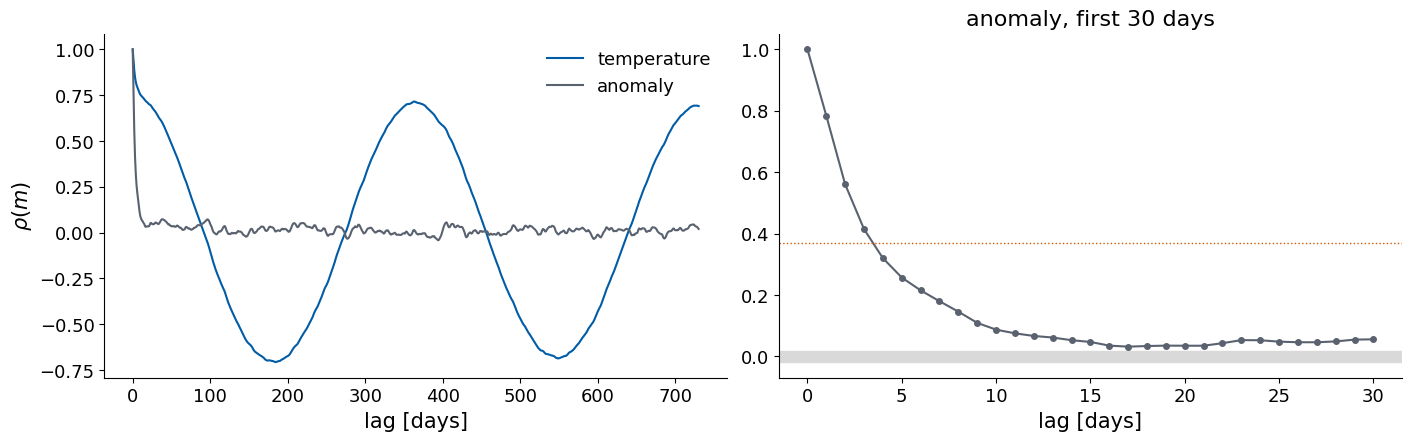

In [8]:
MAX_LAG = 2 * 365
rho_T, rho_a = autocorrelation(temp, MAX_LAG), autocorrelation(anom, MAX_LAG)
fig, axs = plt.subplots(1, 2, figsize=(14, 4.3), layout="constrained")
axs[0].plot(np.arange(MAX_LAG + 1), rho_T, color=UJBlue, label="temperature")
axs[0].plot(np.arange(MAX_LAG + 1), rho_a, color=UJGray, label="anomaly")
axs[0].set_xlabel("lag [days]"); axs[0].set_ylabel(r"$\rho(m)$"); axs[0].legend()
axs[1].plot(np.arange(31), rho_a[:31], "o-", color=UJGray, ms=4)
axs[1].axhline(np.exp(-1), color=DSOrange, ls=":", lw=1)
axs[1].axhspan(-2 / np.sqrt(len(anom)), 2 / np.sqrt(len(anom)), color="0.85", zorder=0)
axs[1].set_xlabel("lag [days]"); axs[1].set_title("anomaly, first 30 days")
plt.show()
print(f"temperature: rho at 1, 182, 365 days = {np.round(rho_T[[1, 182, 365]], 3)}")
print(f"anomaly: rho at 1, 2, 5, 10, 20 days = {np.round(rho_a[[1, 2, 5, 10, 20]], 3)}, "
      f"correlation time {correlation_time(rho_a)} days")

The autocorrelation of the temperature is 0.944 at one day, −0.702 at 182 days and 0.712 at 365 days. It oscillates with the period of one year, since the temperature half a year later is in the opposite season, and its high value at one day is mostly the seasonal cycle. The correlations in the anomaly decay much faster. Its autocorrelation is 0.784 at one day, 0.560 at two days, 0.257 at five days, 0.087 at ten days and 0.034 at twenty days, and it drops below 1/e after 4 days, the correlation time of the weather in central England. Beyond about ten days the anomaly of today says almost nothing about the anomaly to come.

The power spectrum of equation (3) decomposes the variance of the record into periods. A sharp peak marks a cycle with a fixed period, a broad hump an irregular oscillation, and a flat spectrum a record without memory. We plot the raw periodogram and its Welch average on a logarithmic power axis. We compare the temperature with its anomaly, to see which properties belong to the season and which to the weather.

largest periodogram peak of the temperature at f = 1.0058 per year, period 363.1 days
fraction of the variance of the temperature within 0.02 cycles per year of f = 1: 0.66


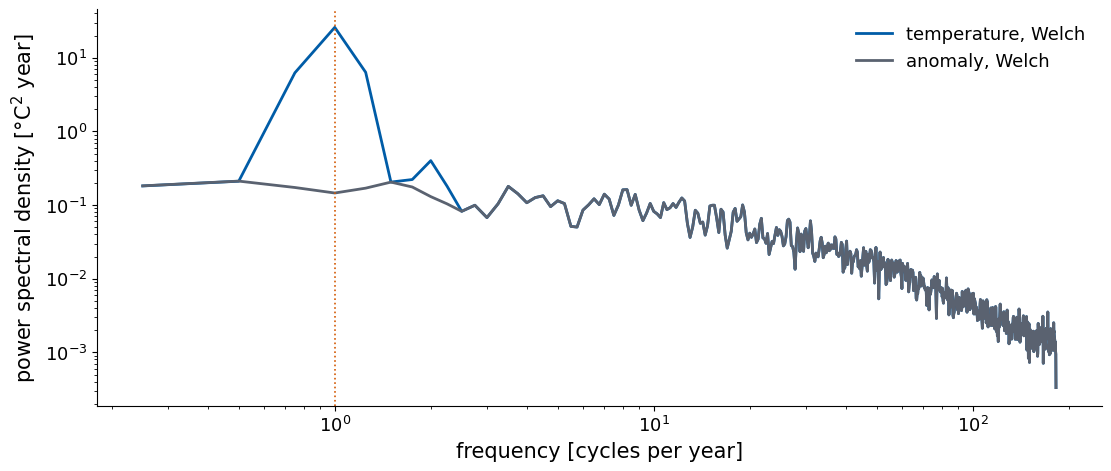

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.6), layout="constrained")
for x, name, col in ((temp, "temperature", UJBlue), (anom, "anomaly", UJGray)):
    f_w, P_w = scipy.signal.welch(x - x.mean(), fs=365.25, nperseg=4 * 365, scaling="density")
    ax.loglog(f_w[1:], P_w[1:] / 2, color=col, lw=2, label=f"{name}, Welch")
f, P = periodogram(temp, 1 / 365.25)
ax.axvline(1, color=DSOrange, ls=":", lw=1.2)
ax.set_xlabel("frequency [cycles per year]"); ax.set_ylabel(r"power spectral density [°C$^2$ year]")
ax.legend()
plt.show()
j_peak = 1 + np.argmax(P[1:])
print(f"largest periodogram peak of the temperature at f = {f[j_peak]:.4f} per year, period {365.25 / f[j_peak]:.1f} days")
print(f"fraction of the variance of the temperature within 0.02 cycles per year of f = 1: "
      f"{P[np.abs(f - 1) < 0.02].sum() / P[1:].sum():.2f}")

The spectrum of the temperature has a peak at one cycle per year, the seasonal cycle. The largest peak of the periodogram lies at 1.0058 cycles per year, a period of 363.1 days, which equals one year within the frequency resolution of the record, and the frequencies within 0.02 cycles per year of it carry 66% of the variance. A smaller peak at two cycles per year comes from the deviation of the seasonal cycle from a pure sinusoid. The spectrum of the anomaly has no peak. It is flat at low frequencies, below a few cycles per year, and falls towards high frequencies. Such a spectrum is called red noise. It is the spectrum of a record with a short memory, whose values a few days apart are correlated and whose values weeks apart are independent, as the autocorrelation showed.

The delay plot draws each value against the value κ samples earlier. It represents both linear and nonlinear dependence between past and future through a two-dimensional delay embedding. We draw it for a short, an intermediate and a long delay. We compare the temperature with its anomaly, to see which properties belong to the season and which to the weather.

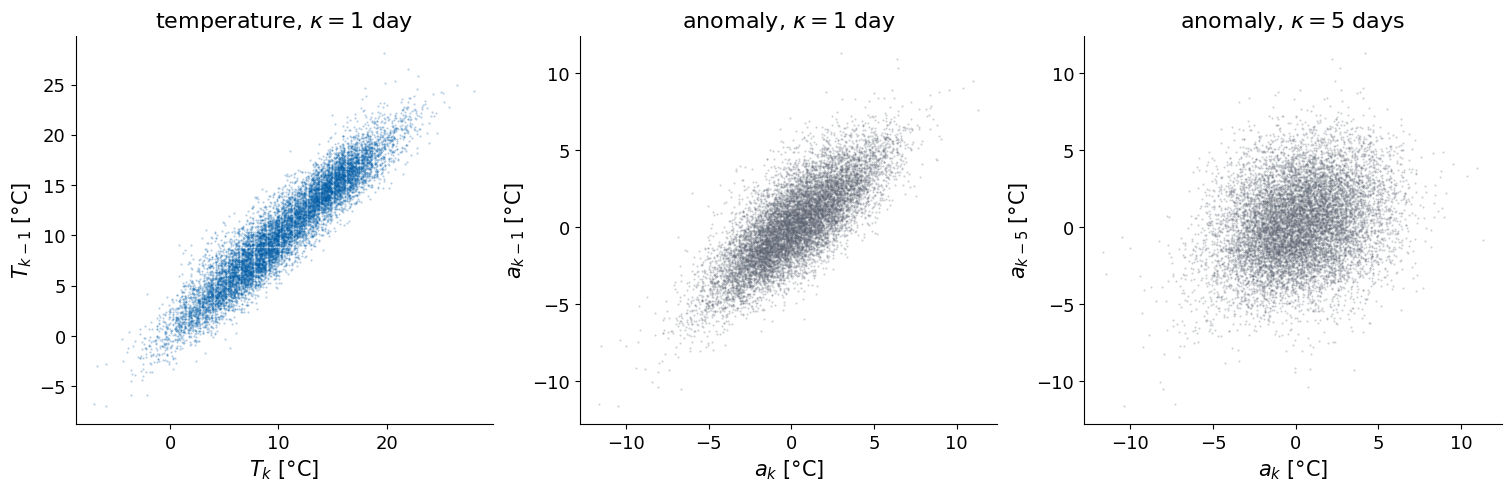

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.8), layout="constrained")
axs[0].plot(temp[1:], temp[:-1], ".", ms=1, alpha=0.3, color=UJBlue)
axs[0].set_xlabel(r"$T_k$ [°C]"); axs[0].set_ylabel(r"$T_{k-1}$ [°C]"); axs[0].set_title(r"temperature, $\kappa=1$ day")
axs[1].plot(anom[1:], anom[:-1], ".", ms=1, alpha=0.3, color=UJGray)
axs[1].set_xlabel(r"$a_k$ [°C]"); axs[1].set_ylabel(r"$a_{k-1}$ [°C]"); axs[1].set_title(r"anomaly, $\kappa=1$ day")
axs[2].plot(anom[5:], anom[:-5], ".", ms=1, alpha=0.3, color=UJGray)
axs[2].set_xlabel(r"$a_k$ [°C]"); axs[2].set_ylabel(r"$a_{k-5}$ [°C]"); axs[2].set_title(r"anomaly, $\kappa=5$ days")
plt.show()

For the temperature, $T_{k-1}$ against $T_k$ lies along a narrow band around the diagonal, since tomorrow is close to today. Most of this alignment comes from the seasonal cycle, which moves both values together through the year. The anomaly at one day forms an elongated cloud, the correlation 0.784, and at five days a nearly round cloud, the correlation 0.257. No curve or loop appears, so there is no sign of a low-dimensional deterministic law in this single record, and the delay plots look like those of a linear stochastic process with a short memory.

### Delay embedding

The hidden state of a deterministic system can be reconstructed from one measured coordinate using the delay vector
$$\mathbf u_k=\big(s_k,\;s_{k-\kappa},\;\dots,\;s_{k-(m-1)\kappa}\big) , \tag{6}$$
built from m values of the record spaced by the delay κ. By the theorem of Takens, for a large enough embedding dimension m the cloud of delay vectors is a faithful picture of the attractor. Mutual information determines κ from the dependence between delayed values, and false nearest neighbours determine m from the geometry of the reconstructed record.

The delay κ is taken at the first local minimum of the mutual information between $s_k$ and $s_{k-\kappa}$ [A. M. Fraser, H. L. Swinney, Phys. Rev. A **33**, 1134 (1986), [doi:10.1103/PhysRevA.33.1134](https://doi.org/10.1103/PhysRevA.33.1134)]. The range of the record is divided into 16 bins of equal width. For a delay κ we count, over all pairs $(s_{k-\kappa},s_k)$, the fraction $p_{ij}(\kappa)$ of pairs whose first value falls into bin i and second value into bin j, and the fractions $p_i$ and $p_j$ of single values in each bin. The mutual information is
$$I(\kappa)=\sum_{i,j}p_{ij}(\kappa)\,\ln\frac{p_{ij}(\kappa)}{p_i\,p_j} , \tag{7}$$
measured in nats. It is zero when the two values are independent, since then $p_{ij}=p_ip_j$ and every logarithm vanishes, and it grows with the dependence of the two values, linear or nonlinear. The autocorrelation of equation (1) measures only the linear part of this dependence. At the first minimum of I(κ) a new delay coordinate adds the most new information while it still belongs to the same stretch of motion.

The embedding dimension m is found with false nearest neighbours [M. B. Kennel, R. Brown, H. D. I. Abarbanel, Phys. Rev. A **45**, 3403 (1992), [doi:10.1103/PhysRevA.45.3403](https://doi.org/10.1103/PhysRevA.45.3403)]. If m is too small, the picture of the attractor is folded onto itself and points from distant parts of the orbit appear as neighbours. For every delay vector $\mathbf u_i^{(m)}$ of dimension m we find its nearest neighbour $\mathbf u_j^{(m)}$, excluding the points with $|i-j|\le w$, which are close only because they are close in time. This exclusion is called the Theiler window. The pair is a false neighbour if the next delay coordinate separates the two points strongly,
$$\frac{\big|s_{i-m\kappa}-s_{j-m\kappa}\big|}{\big\|\mathbf u_i^{(m)}-\mathbf u_j^{(m)}\big\|}>R_{\rm tol}=15 . \tag{8}$$
The fraction of false neighbours is computed for m = 1, 2, …, and the embedding dimension is the smallest m at which it falls below 5%. The ratio test alone is unreliable at large m. The distance between nearest neighbours grows with m, because every added coordinate adds to it, and the ratio of equation (8) becomes small for any record, also for noise. Kennel and co-workers therefore add an absolute test. The pair is also counted as false if its distance in m + 1 dimensions exceeds twice the standard deviation $\sigma_s$ of the record,
$$\frac{\Big(\big\|\mathbf u_i^{(m)}-\mathbf u_j^{(m)}\big\|^2+\big|s_{i-m\kappa}-s_{j-m\kappa}\big|^2\Big)^{1/2}}{\sigma_s}>2 , \tag{9}$$
which identifies neighbours separated by a large distance relative to the variation in the record. We compute both fractions and choose the embedding dimension with the ratio test. The combined fraction, which counts a pair as false under either test, helps to tell a record from a low-dimensional deterministic law from a stochastic record. Its value depends on the record length, the measurement noise and the thresholds. For a low-dimensional deterministic law it stays near zero once the attractor is unfolded. For a stochastic record new random influences enter every coordinate, the nearest neighbours stay far apart in the sense of equation (9), and the combined fraction stays high and grows with m.

The embedding window has the length $(m-1)\kappa+1$ samples and can serve directly as the input of the AR model and of NVAR, with L = m values taken with the stride κ.

In [11]:
from scipy.spatial import cKDTree

def mutual_information(x, max_lag, bins=16):
    # equation (7) for kappa = 0..max_lag, from the same N - max_lag pairs for every delay
    edges = np.linspace(x.min(), x.max(), bins + 1)
    n = len(x) - max_lag
    out = []
    for lag in range(max_lag + 1):
        H, _, _ = np.histogram2d(x[:n], x[lag:lag + n], bins=[edges, edges])
        p = H / n
        pi, pj = p.sum(1, keepdims=True), p.sum(0, keepdims=True)
        nz = p > 0
        out.append(np.sum(p[nz] * np.log(p[nz] / (pi * pj)[nz])))
    return np.array(out)

def first_local_min(c):
    for j in range(1, len(c) - 1):
        if c[j] < c[j - 1] and c[j] <= c[j + 1]:
            return j
    return None

def delay_matrix(x, m, kappa):
    # rows u_k = (x_k, x_(k-kappa), ..., x_(k-(m-1)kappa)) for k = (m-1)kappa .. N-1, equation (6)
    k0 = (m - 1) * kappa
    return np.stack([x[k0 - j * kappa:len(x) - j * kappa] for j in range(m)], axis=1)

def false_neighbour_fraction(x, kappa, m_max=8, w=10, r_tol=15.0, a_tol=2.0):
    # equations (8) and (9) for m = 1..m_max; nearest neighbours outside the Theiler window |i - j| <= w
    # returns the fraction of the ratio test and the fraction of the ratio test or the absolute test
    sigma = x.std()
    fractions, combined = [], []
    for m in range(1, m_max + 1):
        Y = delay_matrix(x, m + 1, kappa)            # first m columns: u^(m); last column: the next delay coordinate
        Ym, extra_col = Y[:, :m], Y[:, m]
        d, j = cKDTree(Ym).query(Ym, k=2 * w + 2)    # at most 2w + 1 points lie inside the window
        i = np.arange(len(Ym))[:, None]
        first = np.argmax(np.abs(j - i) > w, axis=1)
        jj, r = j[np.arange(len(Ym)), first], d[np.arange(len(Ym)), first]
        ok = r > 0                                   # identical vectors give no ratio
        extra = np.abs(extra_col[ok] - extra_col[jj[ok]])
        test_ratio = extra / r[ok] > r_tol
        test_abs = np.sqrt(r[ok] ** 2 + extra ** 2) / sigma > a_tol
        fractions.append(np.mean(test_ratio))
        combined.append(np.mean(test_ratio | test_abs))
    return np.array(fractions), np.array(combined)

def embedding_dimension(fractions, threshold=0.05):
    below = np.flatnonzero(fractions < threshold)
    return int(below[0]) + 1 if below.size else None

first minimum of the mutual information at kappa = 12 samples = 12 days, I(0) = 2.040 nats, I(kappa) = 0.011 nats
false-neighbour fractions for m = 1..8 with kappa = 12 and Theiler window 10
  ratio test            [0.996 0.822 0.321 0.044 0.003 0.    0.    0.   ]
  ratio or absolute test [0.996 0.824 0.345 0.169 0.169 0.188 0.21  0.25 ]
embedding dimension (fraction below 5%): 4, window length (m - 1) kappa + 1 = 37 samples


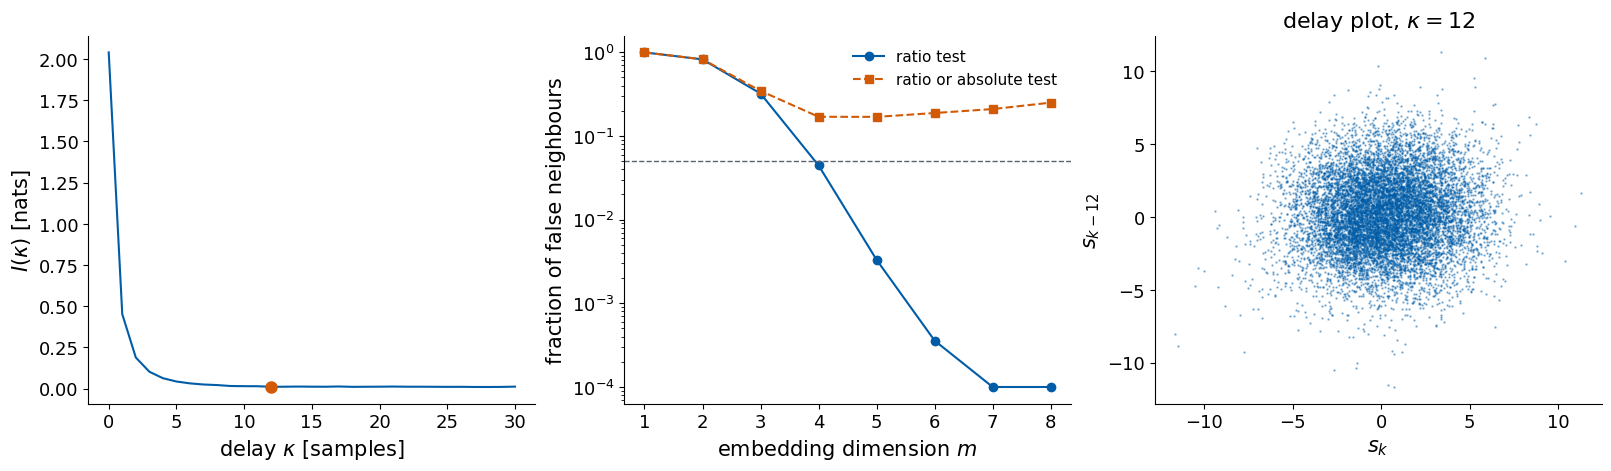

In [12]:
MI = mutual_information(anom, 30)
KAPPA = first_local_min(MI)
FNN, FNN_BOTH = false_neighbour_fraction(anom, KAPPA, m_max=8, w=10)
M_EMB = embedding_dimension(FNN)
print(f"first minimum of the mutual information at kappa = {KAPPA} samples = {KAPPA * 1:.3g} days, "
      f"I(0) = {MI[0]:.3f} nats, I(kappa) = {MI[KAPPA]:.3f} nats")
print(f"false-neighbour fractions for m = 1..8 with kappa = {KAPPA} and Theiler window 10")
print(f"  ratio test            {np.round(FNN, 3)}")
print(f"  ratio or absolute test {np.round(FNN_BOTH, 3)}")
print(f"embedding dimension (fraction below 5%): {M_EMB}"
      + (f", window length (m - 1) kappa + 1 = {(M_EMB - 1) * KAPPA + 1} samples" if M_EMB else ""))
fig, axs = plt.subplots(1, 3, figsize=(16, 4.6), layout="constrained")
axs[0].plot(np.arange(len(MI)), MI, color=UJBlue)
axs[0].plot(KAPPA, MI[KAPPA], "o", color=DSOrange, ms=8)
axs[0].set_xlabel(r"delay $\kappa$ [samples]"); axs[0].set_ylabel(r"$I(\kappa)$ [nats]")
axs[1].semilogy(np.arange(1, 9), np.maximum(FNN, 1e-4), "o-", color=UJBlue, label="ratio test")
axs[1].semilogy(np.arange(1, 9), np.maximum(FNN_BOTH, 1e-4), "s--", color=DSOrange, label="ratio or absolute test")
axs[1].legend(fontsize=11)
axs[1].axhline(0.05, color=UJGray, ls="--", lw=1)
axs[1].set_xlabel("embedding dimension $m$"); axs[1].set_ylabel("fraction of false neighbours")
axs[2].plot(anom[KAPPA:], anom[:-KAPPA], ".", ms=1.5, alpha=0.4, color=UJBlue)
axs[2].set_xlabel(r"$s_k$"); axs[2].set_ylabel(rf"$s_{{k-{KAPPA}}}$"); axs[2].set_title(rf"delay plot, $\kappa = {KAPPA}$")
plt.show()

The following diagnostics describe the full available record, including the later test period. The predictive comparison below recomputes its delay and coordinate count from the fitting block only.

For the anomaly the mutual information falls from 2.040 nats at κ = 0 to 0.011 nats at its first minimum, κ = 12 days, so values twelve days apart share almost no information. The ratio test of equation (8) falls below 5% at m = 4, with 0.044, and to zero from m = 6, which would suggest an embedding window of (4 − 1)·12 + 1 = 37 days. The combined test of equations (8) and (9) behaves differently. It falls to 0.169 at m = 4 and then rises again, to 0.25 at m = 8. One in six nearest neighbours stays far apart in every dimension, the behaviour expected for a stochastic record. A record from a low-dimensional deterministic law would keep the combined fraction near zero once its attractor is unfolded. The short memory of the anomaly is consistent with a stochastic process with a correlation time of a few days, as the autocorrelation function showed.

<hr/>
## 4. Forecasting protocol and scores

The record of length N is split in time order into a fitting block, the first 60% of the samples, a validation block, the next 20%, and a test block, the last 20%. A model is fitted on the fitting block, its settings are chosen by the score on the validation block, AR, NVAR, MA, ARMA and MLP are then refitted on the fitting and validation blocks together before testing. The RNN and LSTM instead retain their best validation checkpoint from fitting-block training; they are not refitted on the combined block. The record is standardised with the mean and the standard deviation of its fitting block. The split follows the time order because a forecast is always made from the past into the future. A random split would put neighbouring, strongly correlated values into the fitting and the test blocks, and the test score would measure how well a model interpolates between known values. Settings chosen on the test block would make its score optimistic, and a separate validation block is therefore used to choose them.

From every origin k the models receive the values up to $s_k$, at most the last L = 20 of them, and forecast $\hat s_{k+\tau}$ for the horizons τ = 1, …, 20, in days. The score at horizon τ is the forecast capacity, the squared Pearson correlation between forecasts and targets over all test origins,
$$C(\tau)=r(\tau)^2,\qquad r(\tau)=\frac{\sum_k\big(\hat s_{k+\tau}-\overline{\hat s}_\tau\big)\big(s_{k+\tau}-\overline s_\tau\big)}{\sqrt{\sum_k\big(\hat s_{k+\tau}-\overline{\hat s}_\tau\big)^2\,\sum_k\big(s_{k+\tau}-\overline s_\tau\big)^2}} , \tag{10}$$
where the bars are averages over the origins at fixed τ. C(τ) is the fraction of the variance of the targets explained by a straight-line fit on the forecasts. It is 1 when the forecasts lie on any straight line against the targets and 0 when they are uncorrelated. The total capacity
$$C_{\rm tot}=\sum_{\tau=1}^{20}C(\tau) \tag{11}$$
has the maximum 20. A forecast without skill still gives C(τ) of about 1/n for n test origins.

Every model is compared with persistence, the forecast that the record keeps its last value,
$$\hat s_{k+\tau}=s_k\quad\text{for every }\tau . \tag{12}$$
Persistence needs no fitting and uses only the newest value. Its capacity follows from the autocorrelation function of equation (1). The correlation between $s_k$ and $s_{k+\tau}$ over the test origins is close to the autocorrelation ρ(τ) of the record at the lag τ, so persistence reaches $C(\tau)\approx\rho(\tau)^2$. A model is useful only where it beats persistence, and the gain over persistence measures what the model has learned beyond the memory of the last value.

In [13]:
SERIES = anom
TAU_MAX, L_MAX = 20, 20
TAUS = np.arange(1, TAU_MAX + 1)
N = len(SERIES)                                    # length of the record used for forecasting
N_FIT, N_VAL = int(0.6 * N), int(0.2 * N)
K0 = L_MAX - 1                                     # first origin with a full window of L_MAX values
O_FIT = np.arange(K0, N_FIT - TAU_MAX)             # origins whose targets lie in the fitting block
O_VAL = np.arange(N_FIT, N_FIT + N_VAL - TAU_MAX)  # ... in the validation block
O_TRAIN = np.arange(K0, N_FIT + N_VAL - TAU_MAX)   # ... in fitting and validation blocks (final fit)
O_TEST = np.arange(N_FIT + N_VAL, N - TAU_MAX)     # ... in the test block
print(f"N = {N}: fitting block 0..{N_FIT - 1}, validation {N_FIT}..{N_FIT + N_VAL - 1}, test {N_FIT + N_VAL}..{N - 1}")
print(f"origins: fit {len(O_FIT)}, validation {len(O_VAL)}, train {len(O_TRAIN)}, test {len(O_TEST)}")
print(f"no-skill floor: 1/n = {1 / len(O_TEST):.4f} per horizon, {TAU_MAX / len(O_TEST):.3f} for C_tot")

def standardise(x):
    # mean and standard deviation of the fitting block only
    return (x - x[:N_FIT].mean()) / x[:N_FIT].std()

def windows(s, origins, L):
    # rows (s_k, s_(k-1), ..., s_(k-L+1)), newest value first; shape (len(origins), L)
    return s[np.asarray(origins)[:, None] - np.arange(L)[None, :]]

def targets(s, origins):
    # Y[i, tau-1] = s_(k_i + tau); shape (len(origins), TAU_MAX)
    return s[np.asarray(origins)[:, None] + TAUS[None, :]]

def capacity(P, Y):
    # C(tau) of equation (15) for every column; a constant forecast has r = 0
    Pc, Yc = P - P.mean(0), Y - Y.mean(0)
    den = np.sqrt((Pc ** 2).sum(0) * (Yc ** 2).sum(0))
    r = np.where(den > 0, (Pc * Yc).sum(0) / np.where(den > 0, den, 1.0), 0.0)
    return r ** 2

# check of capacity against scipy on random numbers
_P, _Y = np.random.default_rng(0).standard_normal((2, 300, 3))
assert np.allclose(capacity(_P, _Y), [scipy.stats.pearsonr(_P[:, j], _Y[:, j]).statistic ** 2 for j in range(3)])

N = 11257: fitting block 0..6753, validation 6754..9004, test 9005..11256
origins: fit 6715, validation 2231, train 8966, test 2232
no-skill floor: 1/n = 0.0004 per horizon, 0.009 for C_tot


We divide the record in time order into fitting, validation and test blocks. At an origin k, the model receives a window of the last L values and forecasts the value τ steps later. The input window is marked in blue and the target in orange. We repeat the forecast at every origin of a block and compare the predictions with the measured values.

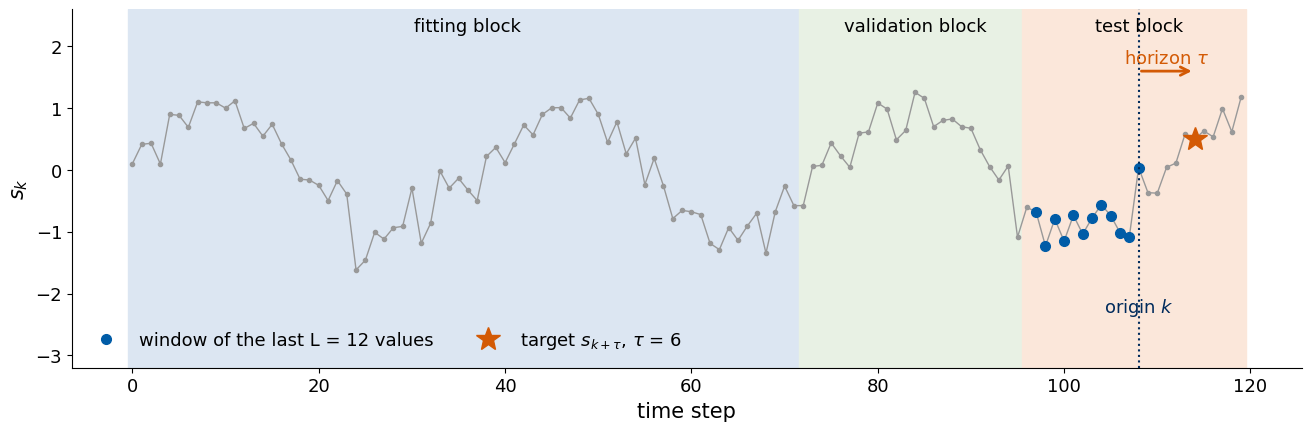

In [14]:
# sketch of the forecasting task: blocks, window of past values, forecast at the horizon tau
rng = np.random.default_rng(1)
t = np.arange(120)
x = np.sin(2 * np.pi * t / 37) + 0.3 * rng.standard_normal(120)
k, L_demo, tau_demo = 108, 12, 6
fig, ax = plt.subplots(figsize=(13, 4.2), layout="constrained")
for (a, b), name, col in (((0, 72), "fitting block", "#DCE6F2"), ((72, 96), "validation block", "#E8F1E4"),
                          ((96, 120), "test block", "#FBE7DA")):
    ax.axvspan(a - 0.5, b - 0.5, color=col, zorder=0)
    ax.text((a + b) / 2, 2.25, name, ha="center", fontsize=13)
ax.plot(t, x, "o-", color="0.6", ms=3, lw=1)
win = np.arange(k - L_demo + 1, k + 1)
ax.plot(win, x[win], "o", color=UJBlue, ms=7, label=f"window of the last L = {L_demo} values")
ax.plot(k + tau_demo, x[k + tau_demo], "*", color=DSOrange, ms=18, label=rf"target $s_{{k+\tau}}$, $\tau$ = {tau_demo}")
ax.annotate("", xy=(k + tau_demo, 1.6), xytext=(k, 1.6), arrowprops=dict(arrowstyle="->", lw=2, color=DSOrange))
ax.text(k + tau_demo / 2, 1.72, r"horizon $\tau$", ha="center", color=DSOrange, fontsize=13)
ax.axvline(k, color=UJNavy, ls=":", lw=1.5); ax.text(k, -2.3, "origin $k$", ha="center", color=UJNavy, fontsize=13)
ax.set_ylim(-3.2, 2.6); ax.set_xlabel("time step"); ax.set_ylabel("$s_k$"); ax.legend(loc="lower left", ncol=2)
plt.show()

For each signal, `plot_scatter` draws the forecasts of every model against the targets at the horizons τ = 1, 5 and 20, one row per model, with the diagonal $\hat s=s$ and the value of C(τ) in each panel. `plot_capacity` draws C(τ) of all models against τ, and `ctot_table` prints the total capacities.

In [15]:
MODEL_COLORS = {"persistence": UJGray, "AR": UJBlue, "MA": "#7FB3E0", "ARMA": UJNavy, "NVAR": "#2A9D8F",
                "MLP": "#E9C46A", "RNN": "#B5651D", "LSTM": DSOrange}

def plot_scatter(name, preds, s, taus=(1, 5, 20)):
    Y = targets(s, O_TEST)
    models = list(preds)
    fig, axs = plt.subplots(len(models), len(taus), figsize=(3.4 * len(taus), 3.0 * len(models)),
                            layout="constrained", squeeze=False)
    lim = np.quantile(np.abs(Y), 0.995) * 1.1
    for i, m in enumerate(models):
        C = capacity(preds[m], Y)
        for j, t in enumerate(taus):
            ax = axs[i, j]
            ax.plot(Y[:, t - 1], preds[m][:, t - 1], ".", ms=3, alpha=0.5, color=MODEL_COLORS.get(m, UJBlue))
            ax.plot([-lim, lim], [-lim, lim], color="0.5", lw=0.8, ls="--")
            ax.set_xlim(-lim, lim)
            ax.text(0.04, 0.96, f"$C={C[t - 1]:.3f}$", transform=ax.transAxes, va="top", fontsize=12)
            if i == 0: ax.set_title(rf"$\tau={t}$")
            if i == len(models) - 1: ax.set_xlabel(r"true $s_{k+\tau}$")
            if j == 0: ax.set_ylabel(f"{m}\n" + r"forecast $\hat s_{k+\tau}$")
    fig.suptitle(name)
    plt.show()

def plot_capacity(results, names, theory=None, ylim=None):
    fig, axs = plt.subplots(1, len(names), figsize=(6.2 * len(names), 4.6), layout="constrained", squeeze=False)
    for ax, name in zip(axs[0], names):
        for m, C in results[name].items():
            ax.plot(TAUS, C, "o-", ms=4, color=MODEL_COLORS.get(m, UJBlue), label=m)
        if theory is not None and name in theory:
            ax.plot(TAUS, theory[name], "k--", lw=1.5, label="theory")
        ax.axhline(1 / len(O_TEST), color="0.6", lw=1, ls=":")
        ax.set_title(name); ax.set_xlabel(r"horizon $\tau$")
        if ylim: ax.set_ylim(*ylim)
    axs[0, 0].set_ylabel(r"$C(\tau)$"); axs[0, -1].legend(fontsize=11, loc="upper right")
    plt.show()

def ctot_table(results):
    tab = pd.DataFrame({name: {m: C.sum() for m, C in res.items()} for name, res in results.items()})
    print("total capacity C_tot = sum of C(tau) over tau = 1..20 (maximum 20)")
    print(tab.round(3).to_string(na_rep="-"))
    return tab

<hr/>
## 5. Models

The models form a sequence of increasing flexibility. Persistence uses only the last value. AR, MA and ARMA are linear in the past values or past errors. NVAR adds products of past values and is still fitted by linear least squares. The MLP learns its own nonlinear features of the window, and the RNN and the LSTM carry a hidden state through the window. Comparing them on the same record shows how much of the future is fixed by linear memory alone and how much more a nonlinear model can extract.

Every model is a function that receives a standardised signal s and returns the forecasts for all test origins and all horizons, an array of shape (number of test origins, 20). Persistence forecasts every horizon by the last value $s_k$. The other seven models use the implementations developed in the lecture notebooks.

1. **AR**, the direct autoregressive model. For every horizon τ a linear readout of the window $(s_k,\dots,s_{k-L+1})$ plus an offset, fitted by ridge regression, all horizons at once as the columns of one target matrix. We choose L from {1, 2, 3, 5, 10, 20} and the ridge strength λ from {10⁻⁶, 10⁻², 1, 100} by $C_{\rm tot}$ on the validation block.
2. **MA**, the moving-average model MA(q), fitted by maximum likelihood with `statsmodels` (`ARIMA` with order (0, 0, q) and a constant). The τ-step forecast iterates the one-step model with the future errors set to zero. The past errors $e_k$ are the residuals of the fitted model on the whole record (`res.apply(s).resid`). We choose q from {1, 2, 3, 5} on the validation block.
3. **ARMA**, the model ARMA(p, q), fitted and iterated in the same way, with (p, q) from {(1, 1), (2, 1), (1, 2), (2, 2)}.
4. **NVAR**, the window of L values with stride κ, every κ-th value, together with all products of two of its entries, and a ridge readout per horizon. We choose L from {2, 3, 5, 8}, κ from {1, 2, 4} and λ as for AR.
5. **MLP**, `sklearn.neural_network.MLPRegressor` with tanh units on the window of the last 20 values, with 20 outputs, one per horizon. We choose one hidden layer of 32 or 64 units and the weight penalty `alpha` from {10⁻³, 10⁻¹, 1} on the validation block, with `early_stopping=True` and `random_state=0`.
6. **RNN**, an Elman recurrent network with 32 hidden units, run over the window of the last 20 values from the oldest to the newest, with a linear readout of the last hidden state to the 20 horizons. We train it with Adam on the mean squared error of the fitting block, with gradient clipping and early stopping on the validation loss.
7. **LSTM**, the same with an LSTM cell.

The direct AR model and NVAR both fit their readouts by ridge regression. For a feature matrix Φ with one row per origin and a target matrix Y with one column per horizon, the ridge loss is
$$\mathcal L(W,\mathbf b)=\big\|Y-\Phi W-\mathbf 1\mathbf b^\top\big\|^2+\lambda\|W\|^2 , \tag{13}$$
where $\mathbf 1$ is a column of ones and $\mathbf b$ the offsets of the horizons. Its minimum follows from the centred matrices $\Phi_c$ and $Y_c$, from which the column means are subtracted,
$$W=(\Phi_c^\top\Phi_c+\lambda I)^{-1}\Phi_c^\top Y_c,\qquad \mathbf b^\top=\overline Y-\overline\Phi\,W , \tag{14}$$
where the bars are the column means, so the offsets are not penalised.

The MA and ARMA models are fitted by maximum likelihood, since their past errors depend on the parameters themselves. With the statsmodels convention, the fitted ARMA(p, q) model reads
$$s_k-\mu=\sum_{i=1}^p\phi_i\,(s_{k-i}-\mu)+e_k+\sum_{j=1}^q\theta_j\,e_{k-j} , \tag{15}$$
where μ is the mean of the process and $e_k$ the one-step error. The τ-step forecast applies equation (15) repeatedly from the origin k, with the forecasts in place of the unknown future values and zero in place of the unknown future errors. An MA(q) forecast therefore returns to μ after q steps.

The functions receive only the record. They use the origins `O_FIT`, `O_VAL`, `O_TRAIN` and `O_TEST` and the functions `windows`, `targets` and `capacity` of Section 4.

In [16]:
CHOSEN = {}          # settings chosen on the validation block, filled in by the forecasters

def forecast_persistence(s):
    # s_(k+tau) is forecast by s_k for every horizon
    return np.repeat(s[O_TEST][:, None], TAU_MAX, axis=1)

In [17]:
def ridge_fit(X, Y, lam):
    # equation (14): ridge regression with an unpenalised offset
    mx, my = X.mean(0), Y.mean(0)
    Xc, Yc = X - mx, Y - my
    W = np.linalg.solve(Xc.T @ Xc + lam * np.eye(X.shape[1]), Xc.T @ Yc)
    return W, my - mx @ W

def ar_features(s, origins, L, stride=1):
    return s[np.asarray(origins)[:, None] - stride * np.arange(L)[None, :]]

def nvar_features(s, origins, L, stride=1):
    U = ar_features(s, origins, L, stride)
    i, j = np.triu_indices(L)                        # all products u_i u_j with i <= j
    return np.concatenate([U, U[:, i] * U[:, j]], axis=1)

LAMS = [1e-6, 1e-2, 1.0, 100.0]

def direct_ridge(s, feature_fn, grid, label):
    best = None
    for hp in grid:
        for lam in LAMS:
            W, b = ridge_fit(feature_fn(s, O_FIT, *hp), targets(s, O_FIT), lam)
            ct = capacity(feature_fn(s, O_VAL, *hp) @ W + b, targets(s, O_VAL)).sum()
            if best is None or ct > best[0]:
                best = (ct, hp, lam)
    _, hp, lam = best
    W, b = ridge_fit(feature_fn(s, O_TRAIN, *hp), targets(s, O_TRAIN), lam)
    CHOSEN[label] = dict(hp=hp, lam=lam)
    return feature_fn(s, O_TEST, *hp) @ W + b

def forecast_ar(s):
    return direct_ridge(s, ar_features, [(L, 1) for L in (1, 2, 3, 5, 10, 20)], "AR")

def forecast_nvar(s):
    grid = [(L, st) for L in (2, 3, 5, 8) for st in (1, 2, 4) if (L - 1) * st <= K0]
    return direct_ridge(s, nvar_features, grid, "NVAR")

# check of ridge_fit against scikit-learn
from sklearn.linear_model import Ridge
_X, _Y = np.random.default_rng(1).standard_normal((200, 6)), np.random.default_rng(2).standard_normal((200, 3))
_W, _b = ridge_fit(_X, _Y, 0.5)
_sk = Ridge(alpha=0.5).fit(_X, _Y)
print(f"max |ridge_fit - sklearn Ridge| = {max(np.abs(_W - _sk.coef_.T).max(), np.abs(_b - _sk.intercept_).max()):.1e}")

max |ridge_fit - sklearn Ridge| = 4.2e-17


In [18]:
def arma_rollout(s, res, p, q, origins):
    par = dict(zip(res.model.param_names, res.params))
    mu = par["const"]
    phi = np.array([par[f"ar.L{i}"] for i in range(1, p + 1)])
    theta = np.array([par[f"ma.L{j}"] for j in range(1, q + 1)])
    e = res.apply(s).resid                           # one-step errors on the whole record, fitted parameters
    P = np.empty((len(origins), TAU_MAX))
    for n, k in enumerate(origins):
        x = list(s[k - p + 1:k + 1] - mu) if p else []
        ee = list(e[k - q + 1:k + 1]) if q else []
        for t in range(TAU_MAX):
            x_new = sum(phi[i] * x[-1 - i] for i in range(p)) + sum(theta[j] * ee[-1 - j] for j in range(q))
            x.append(x_new); ee.append(0.0)          # future errors are set to zero
            P[n, t] = x_new + mu
    return P, e

def arma_select(s, orders, label):
    best = None
    for (p, q) in orders:
        res = ARIMA(s[:N_FIT], order=(p, 0, q), trend="c").fit()
        ct = capacity(arma_rollout(s, res, p, q, O_VAL)[0], targets(s, O_VAL)).sum()
        if best is None or ct > best[0]:
            best = (ct, (p, q))
    p, q = best[1]
    res = ARIMA(s[:N_FIT + N_VAL], order=(p, 0, q), trend="c").fit()
    CHOSEN[label] = dict(order=(p, q))
    return arma_rollout(s, res, p, q, O_TEST)[0], res

def forecast_ma(s):
    return arma_select(s, [(0, q) for q in (1, 2, 3, 5)], "MA")[0]

def forecast_arma(s):
    return arma_select(s, [(1, 1), (2, 1), (1, 2), (2, 2)], "ARMA")[0]

The MLP is the `MLPRegressor` of scikit-learn with one hidden layer of tanh units. It receives the window of the last 20 values and returns 20 outputs, one per horizon, and it is trained on the mean squared error with a weight penalty `alpha`. With `early_stopping=True` it keeps 10% of the fitting data aside and stops when the error on them no longer decreases.

For early stopping scikit-learn holds out a random subset of the fitting windows. The architecture is selected on the chronological validation block, and the forecasts are scored on the later test block.

In [19]:
def forecast_mlp(s):
    best = None
    for width in (32, 64):
        for alpha in (1e-3, 1e-1, 1.0):
            m = MLPRegressor((width,), activation="tanh", alpha=alpha, max_iter=400, early_stopping=True,
                             random_state=0).fit(windows(s, O_FIT, L_MAX), targets(s, O_FIT))
            ct = capacity(m.predict(windows(s, O_VAL, L_MAX)), targets(s, O_VAL)).sum()
            if best is None or ct > best[0]:
                best = (ct, width, alpha)
    _, width, alpha = best
    m = MLPRegressor((width,), activation="tanh", alpha=alpha, max_iter=400, early_stopping=True,
                     random_state=0).fit(windows(s, O_TRAIN, L_MAX), targets(s, O_TRAIN))
    CHOSEN["MLP"] = dict(width=width, alpha=alpha)
    return m.predict(windows(s, O_TEST, L_MAX))

The two recurrent networks read the window of 20 values one value at a time, from the oldest to the newest. The Elman cell updates a hidden state of 32 numbers with one tanh layer that receives the new value and the previous hidden state. The LSTM cell adds a cell state and four gates that decide what is kept, what is written and what is shown. After the last value a linear readout maps the hidden state to the 20 forecasts. Both are trained with the Adam optimiser on the mean squared error of the fitting block, the gradient norm is clipped at 1, and training stops when the error on the validation block has not improved for 20 passes over the data, keeping the best parameters.

In [20]:
orthogonal = nnx.initializers.orthogonal()

class RNNCell(nnx.Module):
    def __init__(self, n_x, n_h, *, rngs):
        self.n_h = n_h
        self.Wx = nnx.Linear(n_x, n_h, rngs=rngs)
        self.Wh = nnx.Linear(n_h, n_h, use_bias=False, kernel_init=orthogonal, rngs=rngs)
    def init_carry(self, B, dtype):
        return jnp.zeros((B, self.n_h), dtype)
    def __call__(self, h, s):
        h = jnp.tanh(self.Wx(s) + self.Wh(h))
        return h, h

class LSTMCell(nnx.Module):
    def __init__(self, n_x, n_h, *, rngs):
        self.n_h = n_h
        self.W = nnx.Linear(n_h + n_x, 4 * n_h, rngs=rngs)                         # blocks (i, f, g, o)
        self.W.bias[...] = self.W.bias[...].at[n_h:2 * n_h].set(1.0)              # forget bias 1
    def init_carry(self, B, dtype):
        return (jnp.zeros((B, self.n_h), dtype), jnp.zeros((B, self.n_h), dtype))
    def __call__(self, carry, s):
        c, h = carry
        a_i, a_f, a_g, a_o = jnp.split(self.W(jnp.concatenate([h, s], axis=-1)), 4, axis=-1)
        c = jax.nn.sigmoid(a_f) * c + jax.nn.sigmoid(a_i) * jnp.tanh(a_g)
        h = jax.nn.sigmoid(a_o) * jnp.tanh(c)
        return (c, h), h

class Recurrent(nnx.Module):
    def __init__(self, cell, n_h, n_out, *, rngs):
        self.cell = cell
        self.head = nnx.Linear(n_h, n_out, rngs=rngs)
    def __call__(self, V):                                                       # V: (B, L, 1), oldest value first
        carry = self.cell.init_carry(V.shape[0], V.dtype)
        _, hs = jax.lax.scan(lambda c, x: self.cell(c, x), carry, jnp.swapaxes(V, 0, 1))
        return self.head(hs[-1])

def fit_recurrent(kind, s, n_h=32, seed=0, epochs=200, patience=20, lr=3e-3, batch=64):
    def data(origins):
        U = windows(s, origins, L_MAX)[:, ::-1, None]                            # oldest value first
        return jnp.asarray(U, jnp.float32), jnp.asarray(targets(s, origins), jnp.float32)
    (Uf, Yf), (Uv, Yv), (Ut, _) = data(O_FIT), data(O_VAL), data(O_TEST)
    rngs = nnx.Rngs(seed)
    model = Recurrent({"RNN": RNNCell, "LSTM": LSTMCell}[kind](1, n_h, rngs=rngs), n_h, TAU_MAX, rngs=rngs)
    graphdef, params, rest = nnx.split(model, nnx.Param, ...)
    tx = optax.chain(optax.clip_by_global_norm(1.0), optax.adam(lr))
    opt_state = tx.init(params)
    loss_fn = lambda p, U, Y: jnp.mean((nnx.merge(graphdef, p, rest)(U) - Y) ** 2)
    n_batches = Uf.shape[0] // batch

    @jax.jit
    def epoch(p, opt_state, key):
        idx = jax.random.permutation(key, Uf.shape[0])[:n_batches * batch].reshape(n_batches, batch)
        def step(carry, ib):
            p, opt_state = carry
            g = jax.grad(loss_fn)(p, Uf[ib], Yf[ib])
            upd, opt_state = tx.update(g, opt_state, p)
            return (optax.apply_updates(p, upd), opt_state), None
        (p, opt_state), _ = jax.lax.scan(step, (p, opt_state), idx)
        return p, opt_state, loss_fn(p, Uv, Yv)

    key, best = jax.random.key(seed), (np.inf, params, 0)
    for ep in range(epochs):
        key, sub = jax.random.split(key)
        params, opt_state, l_val = epoch(params, opt_state, sub)
        if float(l_val) < best[0]:
            best = (float(l_val), params, ep)
        elif ep - best[2] >= patience:
            break
    CHOSEN[kind] = dict(best_epoch=best[2] + 1, epochs_run=ep + 1)
    return np.asarray(nnx.merge(graphdef, best[1], rest)(Ut), np.float64)

def forecast_rnn(s):
    return fit_recurrent("RNN", s)

def forecast_lstm(s):
    return fit_recurrent("LSTM", s)

The function `run_models` applies every implemented model to a standardised record, scores the forecasts with equation (10), stores the capacities and the forecasts, and prints the settings chosen on the validation block.

In [21]:
FORECASTERS = {"persistence": forecast_persistence, "AR": forecast_ar, "MA": forecast_ma, "ARMA": forecast_arma,
               "NVAR": forecast_nvar, "MLP": forecast_mlp, "RNN": forecast_rnn, "LSTM": forecast_lstm}
RESULTS, PREDS, CHOSEN_BY_SERIES = {}, {}, {}

def run_models(name, s, models=tuple(FORECASTERS)):
    # runs every implemented model on the standardised signal s; unimplemented ones are skipped
    RESULTS[name], PREDS[name], CHOSEN_BY_SERIES[name] = {}, {}, {}
    Y = targets(s, O_TEST)
    for m in models:
        t0 = time.time()
        try:
            P = FORECASTERS[m](s)
        except NotImplementedError:
            continue
        PREDS[name][m], RESULTS[name][m] = P, capacity(P, Y)
        CHOSEN_BY_SERIES[name][m] = dict(CHOSEN.get(m, {}))
        info = CHOSEN.get(m, "")
        print(f"{name:14s} {m:12s} C_tot {RESULTS[name][m].sum():7.3f}   C(1) {RESULTS[name][m][0]:.3f}   "
              f"{info}  ({time.time() - t0:.1f} s)")

<hr/>
## 6. Persistence and climatology

Weather forecasters measure every forecast against two references, which need no model of the atmosphere. Persistence forecasts that the weather stays as it is today,
$$\hat T_{k+\tau}=T_k . \tag{16}$$
Climatology forecasts the usual temperature of the target day of the year, here the seasonal cycle of equation (4),
$$\hat T_{k+\tau}=c(t_{k+\tau}) . \tag{17}$$
The two use opposite information. Persistence uses the present weather and ignores the season. Climatology uses the season and ignores the present weather.

Their errors follow from the anomaly. Write the temperature as $T_k=c(t_k)+a_k$, where the anomaly $a_k$ of equation (5) has the mean zero, the variance $\sigma_a^2$ and the autocorrelation function ρ(τ) of equation (1) computed for the anomaly. Angle brackets denote the average over all days. The error of climatology is the anomaly of the target day, so its mean squared error is
$$\big\langle(T_{k+\tau}-c(t_{k+\tau}))^2\big\rangle=\big\langle a_{k+\tau}^2\big\rangle=\sigma_a^2 \tag{18}$$
at every horizon. The error of persistence contains the change of the anomaly and the change of the season between day k and day k + τ. For a few days the change of the season is small, and
$$\big\langle(T_{k+\tau}-T_k)^2\big\rangle\approx\big\langle(a_{k+\tau}-a_k)^2\big\rangle=2\sigma_a^2\big(1-\rho(\tau)\big) , \tag{19}$$
where the square was expanded, $\langle a_k^2\rangle=\langle a_{k+\tau}^2\rangle=\sigma_a^2$, and $\langle a_k a_{k+\tau}\rangle=\sigma_a^2\rho(\tau)$ by the definition of the autocorrelation. Persistence is therefore better than climatology while ρ(τ) > 1/2, and worse afterwards, when its error approaches twice the error of climatology.

The best combination of the two, among forecasts linear in today's anomaly, is damped persistence,
$$\hat T_{k+\tau}=c(t_{k+\tau})+\rho(\tau)\,a_k , \tag{20}$$
which starts from climatology and adds today's anomaly, damped by its autocorrelation. Expanding its squared error in the same way gives the mean squared error $\sigma_a^2(1-\rho(\tau)^2)$, smaller than both references at every horizon, and the factor ρ(τ) is the one that minimises it. It is the AR(1) forecast of the lecture applied to the anomaly, and the models of Section 5 generalise it by using more past values and nonlinear functions of them.

The capacity of equation (10) treats the two references differently from the mean squared error. Climatology follows the large seasonal cycle, so its correlation with the temperature is high although it knows nothing about the weather. We therefore add climatology as a further model. It uses the date of the target day and no measured value.

test block: 2020-08-27 to 2026-10-26
temperature    persistence  C_tot  11.537   C(1) 0.889     (0.0 s)
temperature    climatology  C_tot  14.887   C(1) 0.743     (0.0 s)
temperature    AR           C_tot  12.737   C(1) 0.894   {'hp': (20, 1), 'lam': 100.0}  (0.1 s)


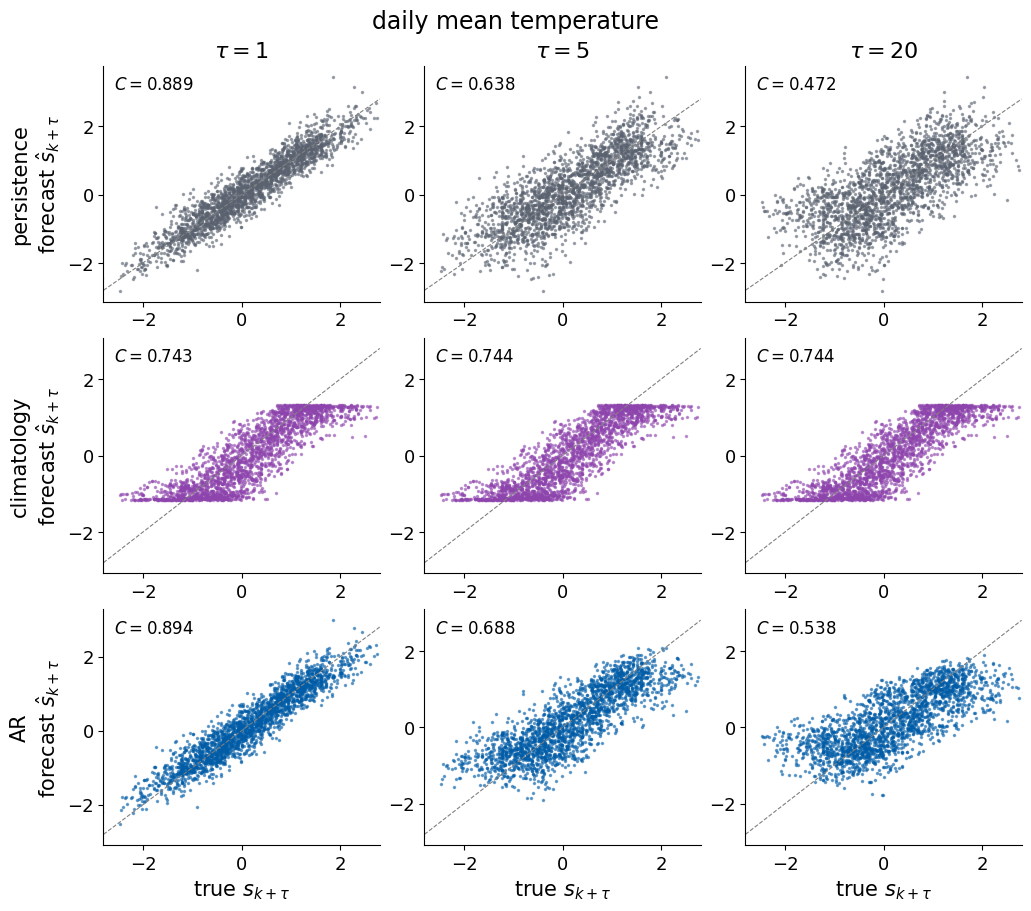

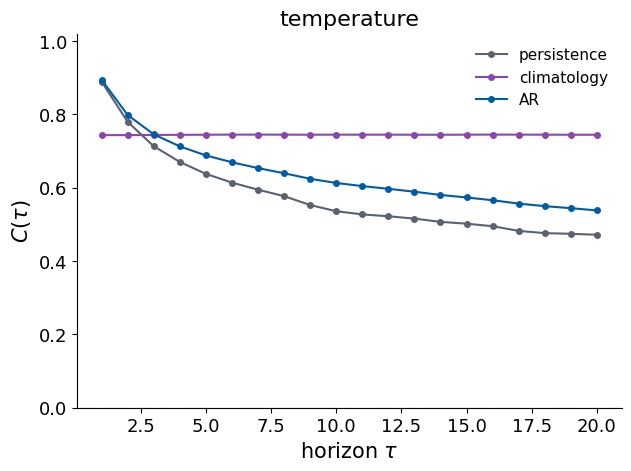

In [22]:
def forecast_climatology(s):
    # the seasonal cycle of the target day, standardised like the record
    return (clim[O_TEST[:, None] + TAUS[None, :]] - temp[:N_FIT].mean()) / temp[:N_FIT].std()

FORECASTERS["climatology"] = forecast_climatology
MODEL_COLORS["climatology"] = "#8E44AD"
s_temp = standardise(temp)
print(f"test block: {cet.Date.iloc[N_FIT + N_VAL].date()} to {cet.Date.iloc[-1].date()}")
run_models("temperature", s_temp, ["persistence", "climatology", "AR"])
plot_scatter("daily mean temperature", PREDS["temperature"], s_temp)
plot_capacity(RESULTS, ["temperature"], ylim=(0, 1.02))

On the temperature, persistence reaches $C_{\rm tot}=11.537$ with C(1) = 0.889, the AR model 12.737 with C(1) = 0.894, and climatology 14.887 with C(1) = 0.743. The test block runs from 27 August 2020 to 26 October 2026. Climatology has the same capacity, about 0.74, at every horizon, since it does not use any measured value. Persistence starts higher and falls below climatology after a few days. These numbers follow equations (18) and (19). The capacity of climatology is the fraction of the variance explained by the seasonal cycle, and persistence is better only while the anomaly of today is still strongly correlated with the anomaly to come.

The high capacities measure the season, and a forecaster gains nothing from a model of the temperature that only reproduces the seasonal cycle, which climatology already predicts. The skill of a weather forecast depends on its ability to predict the anomaly.

<hr/>
## 7. Forecasts of the anomaly

The weather is the anomaly of equation (5). Its forecast is the task of a weather forecaster, and its capacity measures the skill beyond the seasonal cycle.

In [23]:
s_anom = standardise(anom)
run_models("anomaly", s_anom)

anomaly        persistence  C_tot   1.280   C(1) 0.607     (0.0 s)
anomaly        AR           C_tot   1.244   C(1) 0.616   {'hp': (20, 1), 'lam': 100.0}  (0.2 s)
anomaly        MA           C_tot   1.121   C(1) 0.612   {'order': (0, 5)}  (29.5 s)
anomaly        ARMA         C_tot   1.237   C(1) 0.616   {'order': (2, 2)}  (50.0 s)
anomaly        NVAR         C_tot   1.298   C(1) 0.619   {'hp': (3, 1), 'lam': 1e-06}  (0.3 s)
anomaly        MLP          C_tot   1.235   C(1) 0.608   {'width': 32, 'alpha': 1.0}  (11.1 s)
anomaly        RNN          C_tot   1.256   C(1) 0.614   {'best_epoch': 11, 'epochs_run': 31}  (10.3 s)
anomaly        LSTM         C_tot   1.238   C(1) 0.591   {'best_epoch': 2, 'epochs_run': 22}  (10.9 s)


total capacity C_tot = sum of C(tau) over tau = 1..20 (maximum 20)
             temperature  anomaly
persistence       11.537    1.280
climatology       14.887        -
AR                12.737    1.244
MA                     -    1.121
ARMA                   -    1.237
NVAR                   -    1.298
MLP                    -    1.235
RNN                    -    1.256
LSTM                   -    1.238


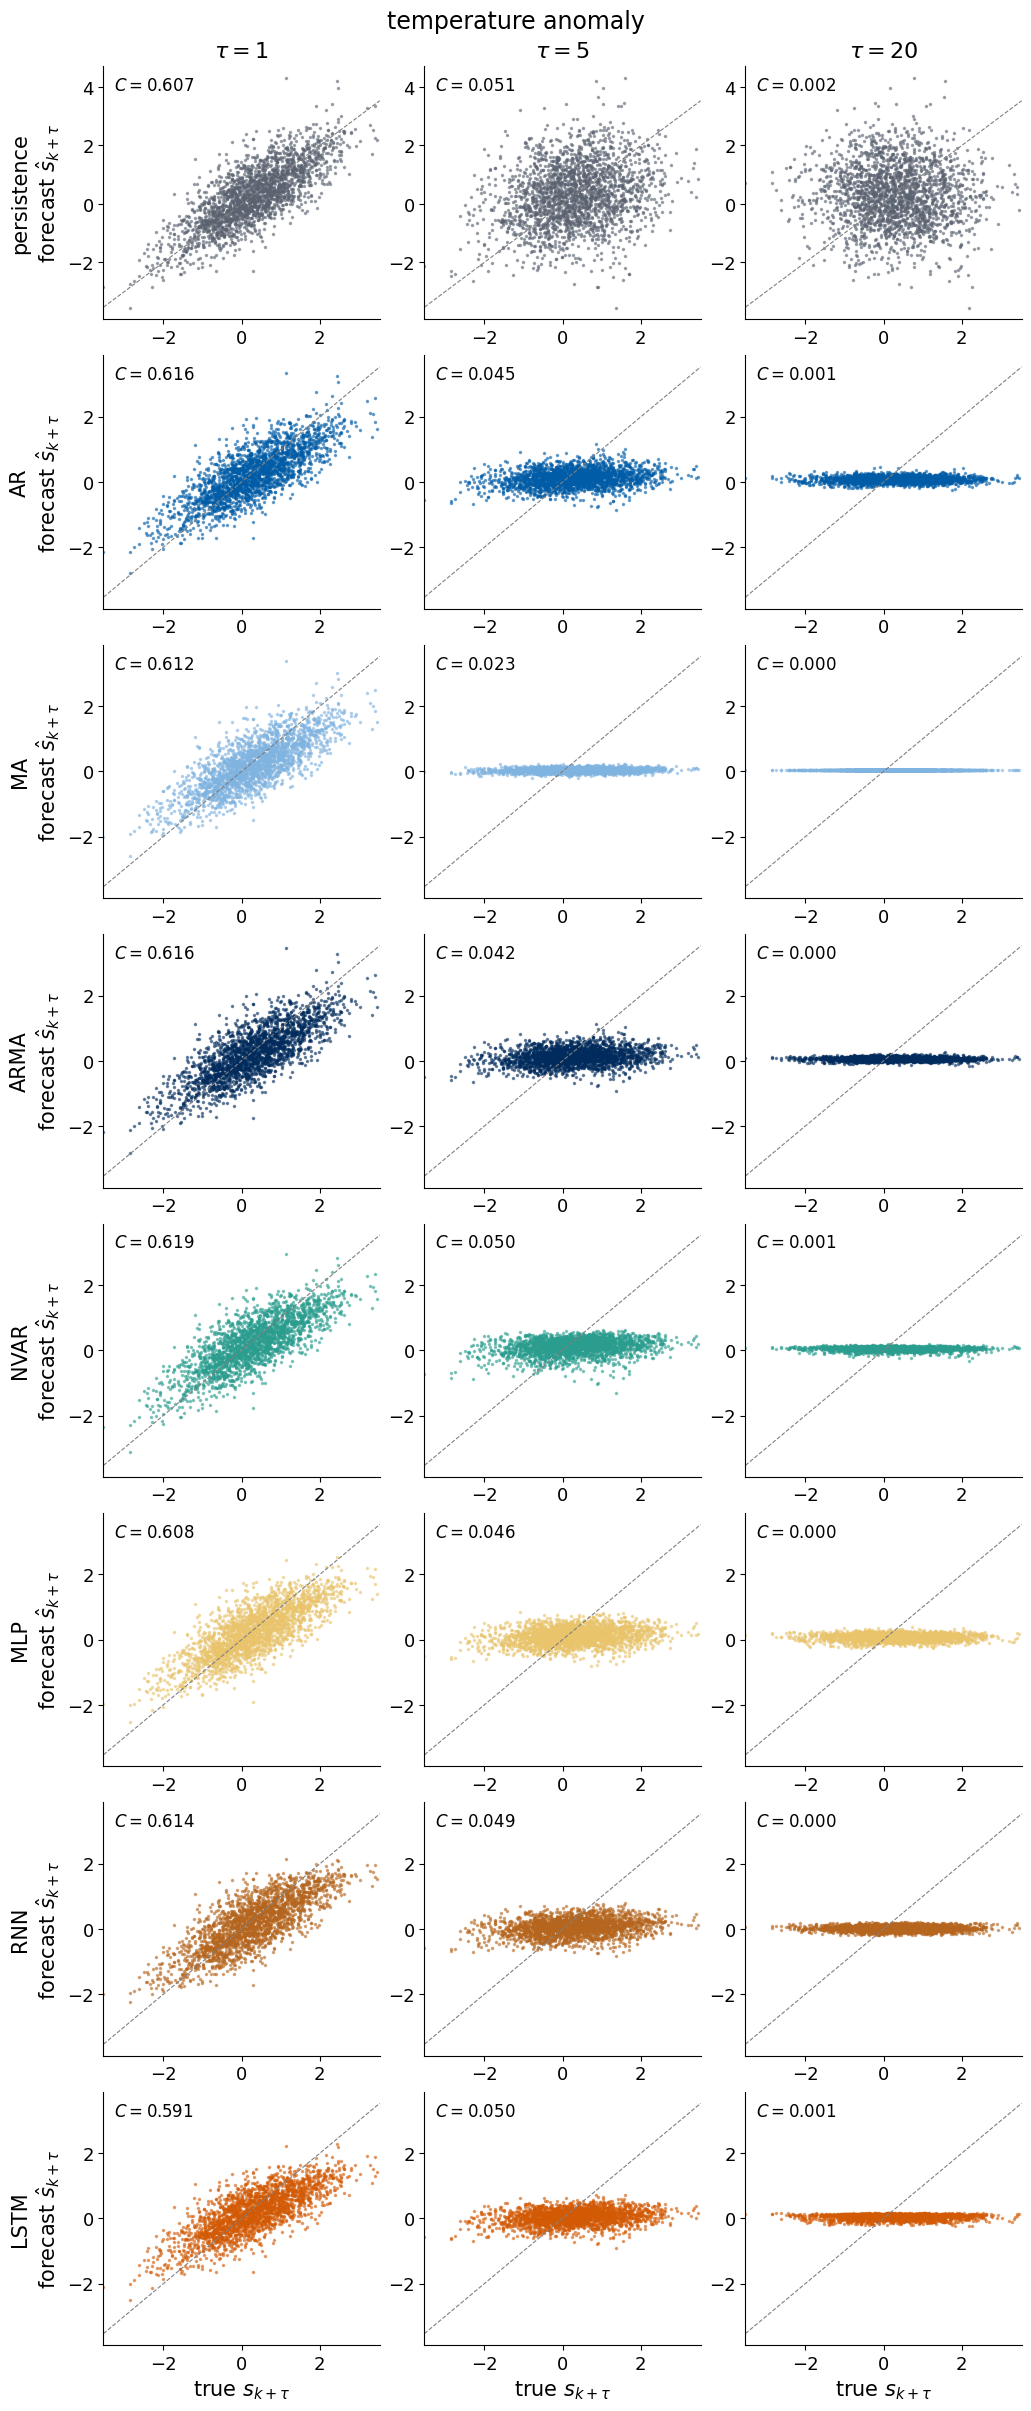

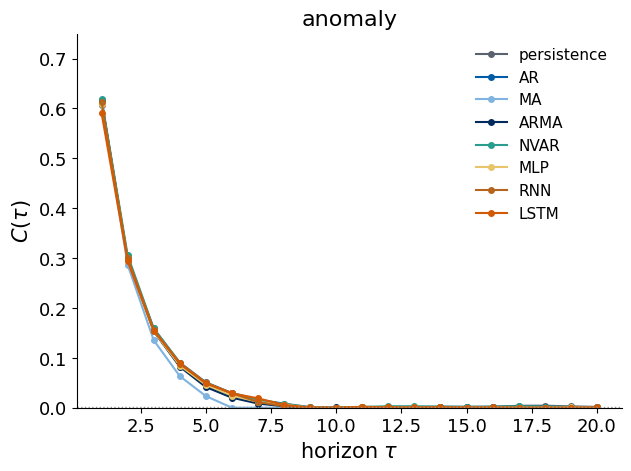

In [24]:
plot_scatter("temperature anomaly", PREDS["anomaly"], s_anom)
plot_capacity(RESULTS, ["anomaly"], ylim=(0, 0.75))
ctot_table(RESULTS);

On the anomaly all eight models reach nearly the same capacity. NVAR has $C_{\rm tot}$ = 1.298, persistence 1.280, the RNN 1.256, AR 1.244, the LSTM 1.238, ARMA 1.237, the MLP 1.235 and MA 1.121. C(1) lies between 0.591 and 0.619, close to the square of the autocorrelation at one day, 0.784² = 0.615, and C(τ) falls to about 0.05 at five days and to zero by ten days, as the square of the autocorrelation function of the anomaly does. The MA model with q = 5 returns to the mean after five days, which costs it a little at τ = 5 to 8.

The models with more parameters do not beat persistence on this record. The anomaly at one place depends on the movement of weather systems over thousands of kilometres, which a record of the temperature at that place does not contain. From the local record the past fixes only a short exponential memory, the AR(1) behaviour of equation (20), and every model finds it and nothing more. The capacity does not distinguish persistence from damped persistence, since both are proportional to the anomaly of today and equation (10) does not change under a scale factor. The mean squared error does distinguish them, and we use it for the forecasts of the temperature in °C.

For the predictive comparison we choose the delay and coordinate count using only the first 60% of the record, the fitting block. We freeze these values, choose the ridge strength on the validation block, refit the selected readout on fitting plus validation data, and evaluate it on the same test origins as the dense-window models.

In [25]:
# Forecast settings are selected from the fitting block only; full-record plots above are descriptive.
MI_FIT = mutual_information(anom[:N_FIT], 30)
KAPPA_FIT = first_local_min(MI_FIT)
if KAPPA_FIT is None:
    raise ValueError("No fitting-block MI minimum: choose a fallback using fitting/validation data only.")
FNN_FIT, FNN_BOTH_FIT = false_neighbour_fraction(anom[:N_FIT], KAPPA_FIT, m_max=8, w=10)
M_EMB_FIT = embedding_dimension(FNN_FIT)
print(f"fitting-only diagnostics: kappa = {KAPPA_FIT}, m = {M_EMB_FIT}, I(0) = {MI_FIT[0]:.6f}, I(kappa) = {MI_FIT[KAPPA_FIT]:.6f}")
print("combined FNN at m=4 and m=8:", FNN_BOTH_FIT[[3, 7]])

# AR and NVAR on the embedding window: L = m values taken with the stride kappa
def embedding_ridge(s, feature_fn, m, kappa):
    k0 = (m - 1) * kappa
    fit, val, train = O_FIT[O_FIT >= k0], O_VAL[O_VAL >= k0], O_TRAIN[O_TRAIN >= k0]
    best = None
    for lam in LAMS:
        W, b = ridge_fit(feature_fn(s, fit, m, kappa), targets(s, fit), lam)
        ct = capacity(feature_fn(s, val, m, kappa) @ W + b, targets(s, val)).sum()
        if best is None or ct > best[0]:
            best = (ct, lam)
    W, b = ridge_fit(feature_fn(s, train, m, kappa), targets(s, train), best[1])
    return capacity(feature_fn(s, O_TEST, m, kappa) @ W + b, targets(s, O_TEST)), best[1]

EMBED_RESULTS = {}
if M_EMB_FIT is None:
    print("no embedding dimension below 5% false neighbours up to m = 8; the embedding window is not defined")
else:
    for label, fn in (("AR", ar_features), ("NVAR", nvar_features)):
        C_emb, lam = embedding_ridge(s_anom, fn, M_EMB_FIT, KAPPA_FIT)
        EMBED_RESULTS[label] = dict(C=C_emb.copy(), Ctot=float(C_emb.sum()), ridge_penalty=float(lam),
                                   m=int(M_EMB_FIT), kappa=int(KAPPA_FIT))
        print(f"{label:5s} on the embedding window (m = {M_EMB_FIT}, kappa = {KAPPA_FIT}, lambda = {lam:.0e}): C_tot {C_emb.sum():6.3f}   "
              f"validation-chosen window: C_tot {RESULTS['anomaly'][label].sum():6.3f}")

fitting-only diagnostics: kappa = 16, m = 4, I(0) = 2.175352, I(kappa) = 0.018727
combined FNN at m=4 and m=8: [0.17623318 0.27301539]
AR    on the embedding window (m = 4, kappa = 16, lambda = 1e+02): C_tot  1.259   validation-chosen window: C_tot  1.244
NVAR  on the embedding window (m = 4, kappa = 16, lambda = 1e-06): C_tot  1.283   validation-chosen window: C_tot  1.298


On the fitting block the mutual information has its first minimum at κ = 16 days, and the false-nearest-neighbour ratio test falls below 5% at m = 4. The embedding window therefore spans (4 − 1)·16 + 1 = 49 samples. With this window and the ridge penalty chosen on the validation block, AR reaches $C_{\rm tot}=1.259$ and NVAR 1.283, compared with 1.244 and 1.298 for the windows of recent values chosen on the validation block. The combined false-neighbour fraction on the fitting block is 0.176 at m = 4 and 0.273 at m = 8, the behaviour of a stochastic record.

A user of a weather forecast wants the temperature itself, in °C. The forecast of the temperature combines the climatology of the target day with the forecast of the anomaly. We score it, together with persistence, climatology and damped persistence of equation (20), with the capacity and with the root-mean-square error
$$\mathrm{RMSE}(\tau)=\Big[\frac1n\sum_k\big(\hat T_{k+\tau}-T_{k+\tau}\big)^2\Big]^{1/2} , \tag{21}$$
the typical size of the error in °C over the n test origins. Unlike the capacity, the RMSE changes when a forecast is scaled or shifted, so it distinguishes a forecast that has the right size from one that is only correlated with the target.

The anomaly model in this combination is the one with the highest capacity on the test block among all scored models.

In [26]:
# Exploratory post-test comparison: the model below is selected using test scores.
best = max(RESULTS["anomaly"], key=lambda m: RESULTS["anomaly"][m].sum())
a_mu, a_sd = anom[:N_FIT].mean(), anom[:N_FIT].std()
T_hat = clim[O_TEST[:, None] + TAUS[None, :]] + PREDS["anomaly"][best] * a_sd + a_mu
C_comb = capacity(T_hat, temp[O_TEST[:, None] + TAUS[None, :]])
C_clim = RESULTS["temperature"]["climatology"]
print(f"exploratory test-selected anomaly model: {best}")
print(f"capacity on the temperature at tau = 1, 2, 5, 20: climatology {np.round(C_clim[[0, 1, 4, 19]], 3)}, "
      f"climatology + {best} {np.round(C_comb[[0, 1, 4, 19]], 3)}")
print(f"C_tot on the temperature: climatology {C_clim.sum():.2f}, combined {C_comb.sum():.2f}")
rmse = lambda P, Y: np.sqrt(np.mean((P - Y) ** 2, axis=0))
Y_T = temp[O_TEST[:, None] + TAUS[None, :]]
print(f"root-mean-square error at tau = 1, 5, 20 [°C]: persistence {np.round(rmse(np.repeat(temp[O_TEST][:, None], TAU_MAX, 1), Y_T)[[0, 4, 19]], 2)}, "
      f"climatology {np.round(rmse(clim[O_TEST[:, None] + TAUS[None, :]], Y_T)[[0, 4, 19]], 2)}, "
      f"combined {np.round(rmse(T_hat, Y_T)[[0, 4, 19]], 2)}")
rho_fit = autocorrelation(anom[:N_FIT], TAU_MAX)[1:]                                 # rho(tau) of the fitting block
T_damped = clim[O_TEST[:, None] + TAUS[None, :]] + rho_fit[None, :] * anom[O_TEST][:, None]   # damped persistence
print(f"damped persistence: rmse at tau = 1, 5, 20 {np.round(rmse(T_damped, Y_T)[[0, 4, 19]], 2)} °C, "
      f"C_tot on the temperature {capacity(T_damped, Y_T).sum():.2f}")
print(f"standard deviation of the anomaly in the test block {anom[N_FIT + N_VAL:].std():.2f} °C, "
      f"mean {anom[N_FIT + N_VAL:].mean():.2f} °C")
print(f"total runtime {time.time() - t_start:.0f} s")

# Export the measurements from this execution; keep descriptive and predictive scopes distinct.
import hashlib, json
from pathlib import Path

def result_json_value(value):
    if isinstance(value, dict):
        return {str(key): result_json_value(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [result_json_value(item) for item in value]
    if isinstance(value, np.ndarray):
        return result_json_value(value.tolist())
    if isinstance(value, (np.integer, np.floating, np.bool_)):
        return result_json_value(value.item())
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value

run_results = {
    "schema_version": 1,
    "protocol": {
        "n_samples": N, "n_fit": N_FIT, "n_validation": N_VAL,
        "n_fit_origins": len(O_FIT), "n_validation_origins": len(O_VAL),
        "n_final_fit_origins": len(O_TRAIN), "n_test_origins": len(O_TEST),
        "horizons": TAUS, "dense_window_max": L_MAX,
        "scaling": "mean and standard deviation of fitting block only",
        "refit_on_fit_plus_validation": ["AR", "NVAR", "MA", "ARMA", "MLP"],
        "best_fitting_checkpoint_without_refit": ["RNN", "LSTM"],
        "MLP_early_stopping": "random internal holdout; chronological block selects hyperparameters",
    },
    "diagnostics_descriptive_full_record": {
        "scope": "full forecasting-period anomaly record from 1996; not used to choose predictive embedding settings",
        "mutual_information": MI, "kappa": KAPPA, "m_ratio_threshold": M_EMB,
        "fnn_ratio": FNN, "fnn_combined": FNN_BOTH,
    },
    "diagnostics_predictive_fitting_block": {
        "scope": "first N_FIT samples only; frozen before validation/test scoring",
        "mutual_information": MI_FIT, "kappa": KAPPA_FIT, "m_ratio_threshold": M_EMB_FIT,
        "fnn_ratio": FNN_FIT, "fnn_combined": FNN_BOTH_FIT,
    },
    "capacity": {series: {model: {"C": values, "Ctot": float(values.sum())}
                          for model, values in model_results.items()}
                 for series, model_results in RESULTS.items()},
    "chosen_model_settings": CHOSEN_BY_SERIES,
    "sparse_embedding_comparison": EMBED_RESULTS,
    "software": {"numpy": np.__version__, "pandas": pd.__version__,
                 "scipy": scipy.__version__, "jax": jax.__version__,
                 "flax": flax.__version__, "sklearn": sklearn.__version__,
                 "statsmodels": statsmodels.__version__},
}

run_results["record"] = {
    "source_file": CET_FILE, "source_sha256": hashlib.sha256(Path(CET_FILE).read_bytes()).hexdigest(),
    "full_first_date": str(cet_all.Date.iloc[0].date()), "full_last_date": str(cet_all.Date.iloc[-1].date()),
    "full_n_days": len(cet_all), "missing_values": int(cet_all.Value.isna().sum()), "forecast_first_date": str(cet.Date.iloc[0].date()),
    "forecast_last_date": str(cet.Date.iloc[-1].date()), "forecast_n_days": len(temp),
    "test_first_date": str(cet.Date.iloc[O_TEST[0]].date()), "test_last_date": str(cet.Date.iloc[-1].date()),
    "first_30_complete_year_range": [int(yearly.index[0]), int(yearly.index[29])],
    "last_30_complete_year_range": [int(yearly.index[-30]), int(yearly.index[-1])],
    "first_30_complete_years_mean": float(first30), "last_30_complete_years_mean": float(last30),
    "temperature_mean": float(temp.mean()), "temperature_std": float(temp.std()),
    "anomaly_mean": float(anom.mean()), "anomaly_std": float(anom.std()),
}
run_results["climatology"] = {
    "fit_scope": "first 60 percent of forecasting period", "harmonic_coefficients": coef,
    "mean": float(coef[0]), "annual_amplitude": float(np.hypot(coef[1], coef[2])),
    "fitting_variance_fraction_explained": float(1 - anom[:N_FIT].var() / temp[:N_FIT].var()),
}
run_results["diagnostics_descriptive_full_record"].update(
    temperature_autocorrelation=rho_T, anomaly_autocorrelation=rho_a,
    anomaly_correlation_time_days=correlation_time(rho_a))
_export_rmse = lambda pred: np.sqrt(np.mean((pred - Y_T) ** 2, axis=0))
run_results["physical_error_diagnostics"] = {
    "selection_scope": "exploratory: anomaly model selected by test capacity",
    "selected_anomaly_model": best, "units": "degrees Celsius", "horizons_days": TAUS,
    "RMSE_persistence": _export_rmse(np.repeat(temp[O_TEST][:, None], TAU_MAX, 1)),
    "RMSE_climatology": _export_rmse(clim[O_TEST[:, None] + TAUS[None, :]]),
    "RMSE_climatology_plus_selected_model": _export_rmse(T_hat),
    "RMSE_damped_persistence": _export_rmse(T_damped),
    "capacity_climatology_plus_selected_model": C_comb,
    "capacity_damped_persistence": capacity(T_damped, Y_T),
    "damped_persistence_fit_autocorrelation": rho_fit,
    "test_anomaly_mean": float(anom[N_FIT + N_VAL:].mean()),
    "test_anomaly_std": float(anom[N_FIT + N_VAL:].std()),
}
_export_path = Path("figures/numbers_cet.json")
_export_path.parent.mkdir(parents=True, exist_ok=True)
_export_path.write_text(json.dumps(result_json_value(run_results), indent=2, allow_nan=False) + "\n")
print(f"Fresh-run numeric results written to {_export_path}")


exploratory test-selected anomaly model: NVAR
capacity on the temperature at tau = 1, 2, 5, 20: climatology [0.743 0.743 0.744 0.744], climatology + NVAR [0.902 0.822 0.757 0.743]
C_tot on the temperature: climatology 14.89, combined 15.18
root-mean-square error at tau = 1, 5, 20 [°C]: persistence [1.79 3.36 4.19], climatology [2.8 2.8 2.8], combined [1.67 2.67 2.77]
damped persistence: rmse at tau = 1, 5, 20 [1.69 2.68 2.79] °C, C_tot on the temperature 15.18
standard deviation of the anomaly in the test block 2.68 °C, mean 0.80 °C
total runtime 133 s
Fresh-run numeric results written to figures/numbers_cet.json


The best anomaly model, NVAR, combined with the climatology gives a forecast of the temperature with the capacity 0.902 at one day, 0.822 at two days, 0.757 at five days and 0.743 at twenty days, where it equals the climatology. Its total capacity, 15.18, exceeds those of persistence, 11.54, and of climatology, 14.89. The root-mean-square error leads to the same conclusion in degrees. Persistence has the error 1.79 °C at one day, 3.36 °C at five days and 4.19 °C at twenty days. Climatology has 2.8 °C at every horizon. The combined forecast has 1.67, 2.67 and 2.77 °C, below both references at every horizon. Damped persistence of equation (20), with ρ(τ) measured on the fitting block, has 1.69, 2.68 and 2.79 °C and the same total capacity, 15.18, so the neural networks and NVAR add almost nothing to the simplest combination of the two references.

The error of persistence at twenty days, 4.19 °C, is 1.5 times the error of climatology, close to the factor √2 ≈ 1.41 of equation (19) for independent days, with the change of the season over twenty days on top. The test block is warmer than the climatology of the fitting block, with an anomaly of mean 0.80 °C and standard deviation 2.68 °C, and this warming also enters the error of climatology. Weather services reach a useful horizon of about a week because they integrate the equations of the whole atmosphere from measurements all over the globe. A model that sees only the temperature at one place learns the short memory of the local weather, a correlation time of 4 days, and this sets the horizon of every model that uses this record alone.

## References

- Met Office Hadley Centre, *HadCET daily mean temperature*, version 2.1, <https://www.metoffice.gov.uk/hadobs/hadcet/>, Open Government Licence v3.0
- D. E. Parker, T. P. Legg, C. K. Folland, *A new daily central England temperature series, 1772–1991*, Int. J. Climatol. **12**, 317 (1992), [doi:10.1002/joc.3370120402](https://doi.org/10.1002/joc.3370120402)
- T. Legg, D. Packman, G. Caton Harrison, M. McCarthy, *An update to the Central England Temperature series, HadCET v2.1*, Geosci. Data J. **12**, e284 (2025), [doi:10.1002/gdj3.284](https://doi.org/10.1002/gdj3.284)
- E. N. Lorenz, *Deterministic nonperiodic flow*, J. Atmos. Sci. **20**, 130 (1963), [doi:10.1175/1520-0469(1963)020<0130:DNF>2.0.CO;2](https://doi.org/10.1175/1520-0469(1963)020<0130:DNF>2.0.CO;2)
- D. J. Gauthier, E. Bollt, A. Griffith, W. A. S. Barbosa, *Next generation reservoir computing*, Nat. Commun. **12**, 5564 (2021), [doi:10.1038/s41467-021-25801-2](https://doi.org/10.1038/s41467-021-25801-2)